# **Land Use and Land Cover Classification of Naivasha Sub-County (2016–2025)**
This notebook presents a workflow for mapping and analysing land use and land cover changes in Naivasha Sub-County, Kenya, for the years 2016, 2020, and 2025 using Sentinel-2 multispectral satellite imagery within the Google Earth Engine (GEE) cloud computing platform. A Random Forest (RF) supervised machine learning classifier is employed to generate LULC maps from spectral information extracted from the satellite imagery.

# PART 1: DATA PREPARATION

## Introduction

This section prepares the computational environment required for land use and land cover (LULC) classification. It installs the necessary Python libraries, initializes Google Earth Engine, defines the study parameters, creates the project folder structure, and loads the study area boundary.


### Objectives

- Install all required Python packages.
- Import the required libraries.
- Authenticate and initialize Google Earth Engine.
- Define global analysis parameters.
- Create output folders.
- Load and visualize the study area.


In [ ]:
# INSTALL REQUIRED LIBRARIES
!pip -q install geemap geopandas earthengine-api --upgrade
!pip install -q cartopy
!pip install -q contextily mercantile
!pip install -q contextily mercantile matplotlib-scalebar


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 480.5/480.5 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 80.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 57.6 MB/s eta 0:00:00


In [ ]:
# Import necessary libraries
import ee
import geemap
import geopandas as gpd
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

print("Libraries successfully imported")

Libraries successfully imported


In [ ]:
# Initializing Google Earth Engine
# Google Earth Engine project ID

PROJECT_ID = "ee-2621kimanimunga"

try:

    ee.Initialize(project=PROJECT_ID)

    print("Google Earth Engine initialized successfully.")

except:

    print("Authentication required...")

    ee.Authenticate()

    ee.Initialize(project=PROJECT_ID)

    print("Earth Engine authentication completed.")

Authentication required...
Earth Engine authentication completed.


In [ ]:
# DEFINING GLOBAL PARAMETERS
# Years selected for LULC mapping
YEARS = [2016, 2020, 2025]

# Seasonal composite period
START_MONTH = 1
END_MONTH = 3

# Maximum allowable cloud cover (%)
MAX_CLOUD = 20

# Spatial resolution (m)
SCALE = 10

# Random seed
SEED = 42

# Number of trees for Random Forest
RF_TREES = 200

print("Global parameters loaded.")

Global parameters loaded.


In [ ]:
# CREATING PROJECT DIRECTORY STRUCTURE
OUTPUT_DIR = Path("Outputs")
COMPOSITE_DIR = OUTPUT_DIR / "Composites"
TRAINING_DIR = OUTPUT_DIR / "Training"
CLASSIFIED_DIR = OUTPUT_DIR / "Classification"
ACCURACY_DIR = OUTPUT_DIR / "Accuracy"
FIGURE_DIR = OUTPUT_DIR / "Figures"
TABLE_DIR = OUTPUT_DIR / "Tables"
for folder in [
    OUTPUT_DIR,
    COMPOSITE_DIR,
    TRAINING_DIR,
    CLASSIFIED_DIR,
    ACCURACY_DIR,
    FIGURE_DIR,
    TABLE_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)
print("Output folders created successfully.")

Output folders created successfully.


In [ ]:
# LOADING STUDY AREA
# Read Naivasha Sub County boundary
AOI = gpd.read_file("NaivashaSubCountyBoundary.shp")
# Ensure CRS exists
if AOI.crs is None:
    AOI = AOI.set_crs("EPSG:4326")
# Convert to WGS84
AOI = AOI.to_crs("EPSG:4326")
# Convert to Earth Engine FeatureCollection
AOI_EE = geemap.geopandas_to_ee(AOI)
print(AOI.head())

   OBJECTID FIRST_DIVI  Shape_Leng  Shape_Area  \
0       319   Naivasha    2.071567     0.12921   

                                            geometry  
0  POLYGON ((36.27087 -0.65656, 36.28161 -0.66341...  


In [ ]:
# VISUALIZE STUDY AREA MAP
Map = geemap.Map()
Map.centerObject(AOI_EE,10)
# Add OpenStreetMap basemap
Map.add_basemap("OpenStreetMap")
# Add study boundary
Map.addLayer(
    AOI_EE.style(color="red", fillColor="00000000", width=3),
    {},
    "Naivasha Boundary"
)
# Add layer control
Map.addLayerControl()
Map

Map(center=[-0.8830196063331436, 36.38746421367366], controls=(WidgetControl(options=['position', 'transparent…

Study area map successfully saved to Outputs/Figures/Naivasha_Study_Area_Map.png


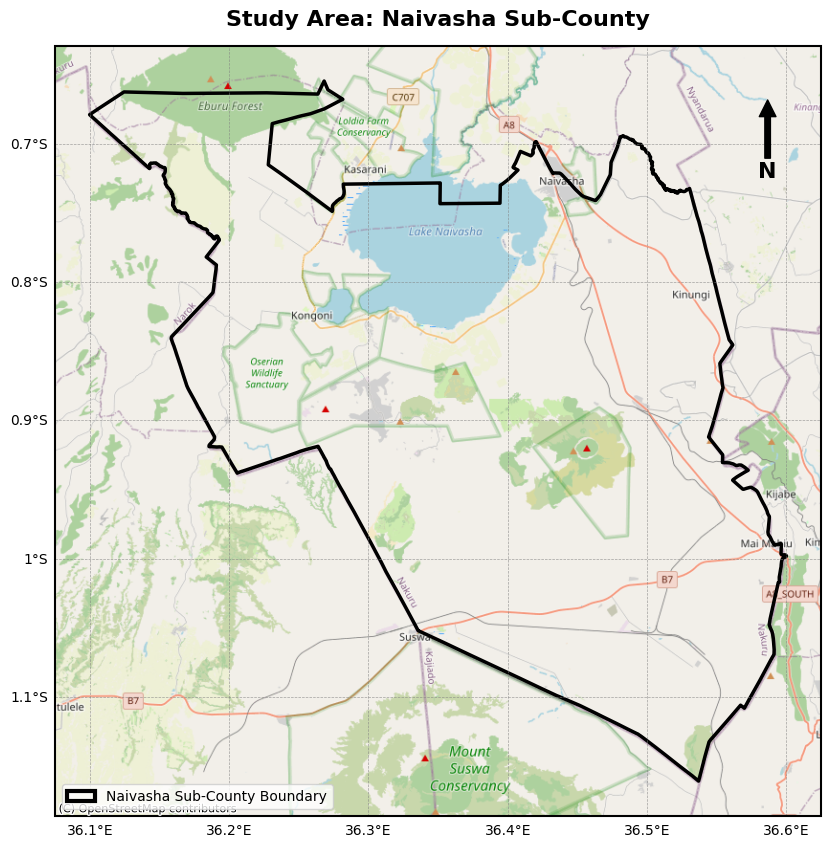

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import contextily as ctx
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.patches import Patch

# Ensure FIGURE_DIR exists
FIGURE_DIR = Path("Outputs") / "Figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# 1. Re-project AOI to Web Mercator (EPSG:3857) for contextily basemap compatibility
AOI_mercator = AOI.to_crs(epsg=3857)

# 2. Set up the figure and Cartopy projection
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={'projection': ccrs.Mercator()})

# 3. Plot the study area boundary
AOI_mercator.plot(
    ax=ax,
    transform=ccrs.Mercator(),
    facecolor='none',
    edgecolor='black',
    linewidth=2.5,
    zorder=2
)

# 4. Add OpenStreetMap static basemap tiles
ctx.add_basemap(
    ax,
    crs=AOI_mercator.crs.to_string(),
    source=ctx.providers.OpenStreetMap.Mapnik,
    zoom=11,
    attribution_size=8
)

# 5. Configure gridlines (Graticules)
gl = ax.gridlines(
    draw_labels=True,
    linestyle="--",
    linewidth=0.5,
    color="grey",
    alpha=0.7
)
gl.top_labels = False
gl.right_labels = False

# 6. Title
ax.set_title(
    "Study Area: Naivasha Sub-County",
    fontsize=16,
    fontweight="bold",
    pad=15
)
# 7. North Arrow
ax.annotate(
    'N',
    xy=(0.93, 0.93),
    xytext=(0.93, 0.83),
    xycoords='axes fraction',
    arrowprops=dict(
        facecolor='black',
        width=4,
        headwidth=12
    ),
    ha='center',
    fontsize=16,
    fontweight='bold'
)
# 9. Legend
legend_patch = Patch(
    facecolor='none',
    edgecolor='black',
    linewidth=3,
    label='Naivasha Sub-County Boundary'
)
ax.legend(
    handles=[legend_patch],
    loc="lower left",
    frameon=True,
    fontsize=10
)
# 10. Neatline and Output Save
for spine in ax.spines.values():
    spine.set_linewidth(1.5)

output_map_path = FIGURE_DIR / "Naivasha_Study_Area_Map.png"
plt.savefig(
    output_map_path,
    dpi=600,
    bbox_inches="tight"
)
print(f"Study area map successfully saved to {output_map_path}")
plt.show()
plt.close(fig)

# PART 2: SENTINEL-2 IMAGE PREPROCESSING AND SPECTRAL INDEX GENERATION

## Introduction

Satellite image preprocessing is a critical step in land use and land cover classification. Raw Sentinel-2 imagery often contains clouds, cloud shadows, and atmospheric effects that can negatively affect classification accuracy. Therefore, preprocessing is performed to generate clean, cloud-free annual composites that accurately represent the land surface.

In this study, Sentinel-2 Level-2A Surface Reflectance imagery is used. Images acquired during the dry season (January–March) are selected to minimize seasonal vegetation variability and cloud contamination. A cloud masking procedure is applied using the Sentinel-2 Scene Classification Layer (SCL), after which annual median composites are generated.

Several spectral indices are then computed and added to the imagery to improve class separability during Random Forest classification.

---

## Objectives

- Retrieve Sentinel-2 imagery from Google Earth Engine.
- Remove clouds and cloud shadows.
- Generate annual median composites.
- Calculate spectral indices.
- Visualize the processed imagery.

In [ ]:
# CLOUD MASKING FUNCTION

def mask_clouds(image):

    scl = image.select("SCL")

    mask = (
        scl.neq(3)      # Cloud shadow
        .And(scl.neq(8))   # Medium cloud
        .And(scl.neq(9))   # High cloud
        .And(scl.neq(10))  # Cirrus
        .And(scl.neq(11))  # Snow
    )

    return (
        image
        .updateMask(mask)
        .divide(10000)
        .copyProperties(image, image.propertyNames())
    )

In [ ]:
# CREATE ANNUAL MEDIAN COMPOSITE
def create_composite(year):

    start = ee.Date.fromYMD(year, START_MONTH, 1)
    end = ee.Date.fromYMD(year, END_MONTH, 31)

    collection = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(AOI_EE)
        .filterDate(start, end)
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", MAX_CLOUD))
        .map(mask_clouds)
    )

    composite = (
        collection
        .median()
        .clip(AOI_EE)
    )

    return composite

In [ ]:
# CALCULATING SPECTRAL INDICES
def add_indices(image):

    # Normalized Difference Vegetation Index
    ndvi = image.normalizedDifference(
        ["B8", "B4"]
    ).rename("NDVI")

    # Enhanced Vegetation Index
    evi = image.expression(

        '2.5*((NIR-RED)/(NIR+6*RED-7.5*BLUE+1))',

        {
            'NIR': image.select('B8'),
            'RED': image.select('B4'),
            'BLUE': image.select('B2')
        }

    ).rename("EVI")

    # Soil Adjusted Vegetation Index
    savi = image.expression(

        '((NIR-RED)/(NIR+RED+0.5))*1.5',

        {
            'NIR': image.select("B8"),
            'RED': image.select("B4")
        }

    ).rename("SAVI")

    # Normalized Difference Water Index
    ndwi = image.normalizedDifference(

        ["B3", "B8"]

    ).rename("NDWI")

    # Normalized Difference Built-up Index
    ndbi = image.normalizedDifference(

        ["B11", "B8"]

    ).rename("NDBI")

    # Bare Soil Index
    bsi = image.expression(

        '((SWIR+RED)-(NIR+BLUE))/((SWIR+RED)+(NIR+BLUE))',

        {

            'SWIR': image.select('B11'),

            'RED': image.select('B4'),

            'NIR': image.select('B8'),

            'BLUE': image.select('B2')

        }

    ).rename("BSI")

    return image.addBands([
        ndvi,
        evi,
        savi,
        ndwi,
        ndbi,
        bsi
    ])

In [ ]:
# GENERATING ANNUAL IMAGE COMPOSITES
images = {}

for year in YEARS:

    print(f"Processing Sentinel-2 Composite: {year}")

    composite = create_composite(year)

    composite = add_indices(composite)

    images[year] = composite

print("All annual composites successfully created.")

Processing Sentinel-2 Composite: 2016
Processing Sentinel-2 Composite: 2020
Processing Sentinel-2 Composite: 2025
All annual composites successfully created.


In [ ]:
#  VISUALIZING RGB COMPOSITES
RGB_VIS = {
    "bands": ["B4", "B3", "B2"],
    "min": 0,
    "max": 0.30,
    "gamma": 1.2
}
Map = geemap.Map()
Map.centerObject(AOI_EE,10)
for year in YEARS:
    Map.addLayer(
        images[year],
        RGB_VIS,
        f"RGB Composite {year}"
    )
Map.addLayer(
    AOI_EE.style(
        color="red",
        fillColor="00000000",
    ),
    {},    "Study Area"

)
Map.addLayerControl()
Map

Map(center=[-0.8830196063331436, 36.38746421367366], controls=(WidgetControl(options=['position', 'transparent…

Exporting RGB Composite for 2016...
Generating URL ...
Please wait ...
Data downloaded to /content/Outputs/Figures/RGB_Composite_2016.tif
Exporting RGB Composite for 2020...
Generating URL ...
Please wait ...
Data downloaded to /content/Outputs/Figures/RGB_Composite_2020.tif
Exporting RGB Composite for 2025...
Generating URL ...
Please wait ...


Data downloaded to /content/Outputs/Figures/RGB_Composite_2025.tif


Annual composites map successfully saved to Outputs/Figures/Sentinel2_Annual_Composites_Comparison.png


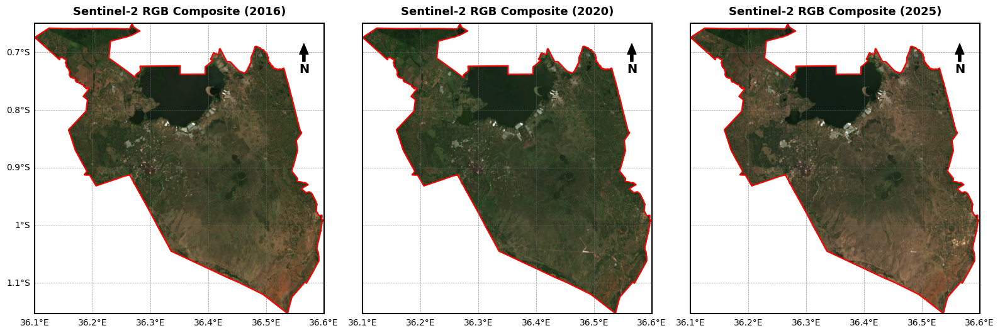

In [ ]:
import rasterio
from rasterio.plot import plotting_extent
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib_scalebar.scalebar import ScaleBar
from pathlib import Path
import geemap
import ee
import numpy as np

# Ensure FIGURE_DIR exists
FIGURE_DIR = Path("Outputs") / "Figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# 1. Export annual RGB composites locally for plotting with a coarser scale to bypass size limits
rgb_tifs = {}
for year in YEARS:
    tif_path = str(FIGURE_DIR / f"RGB_Composite_{year}.tif")
    print(f"Exporting RGB Composite for {year}...")

    # Select RGB bands and scale
    rgb_image = images[year].select(["B4", "B3", "B2"]).multiply(3.3).clip(AOI_EE)

    geemap.ee_export_image(
        rgb_image,
        filename=tif_path,
        scale=60,  # Coarser scale to avoid size limits
        region=AOI_EE.geometry(),
        file_per_band=False
    )
    rgb_tifs[year] = tif_path

# 2. Set up a 1-row by 3-column subplot grid using PlateCarree projection with a white figure background
fig, axes = plt.subplots(1, 3, figsize=(16, 6), subplot_kw={'projection': ccrs.PlateCarree()})
fig.patch.set_facecolor('white')

for idx, year in enumerate(YEARS):
    ax = axes[idx]
    ax.set_facecolor('white')

    with rasterio.open(rgb_tifs[year]) as src:
        img_data = src.read([1, 2, 3]) # Read R, G, B
        img_data = np.moveaxis(img_data, 0, -1)
        extent = plotting_extent(src)
        no_data_mask = (img_data[:, :, 0] == 0) & (img_data[:, :, 1] == 0) & (img_data[:, :, 2] == 0)
        if img_data.dtype != np.float32 and img_data.dtype != np.float64:
            img_data = img_data.astype(np.float32) / 255.0 # Ensure float for comparison and assignment
        img_data[no_data_mask] = [1.0, 1.0, 1.0] # Set to white (normalized)

    # Plot image with PlateCarree data transform matching WGS84 (EPSG:4326) exported bounds
    ax.imshow(
        img_data,
        extent=extent,
        origin="upper",
        transform=ccrs.PlateCarree()
    )

    # Set exact map boundary limits to fit the raster cleanly
    ax.set_extent([extent[0], extent[1], extent[2], extent[3]], crs=ccrs.PlateCarree())

    # Plot AOI boundary overlay on each panel
    AOI.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="red",
        linewidth=1.5
    )

    # Gridlines with distinct dark grey lines for white background
    gl = ax.gridlines(
        draw_labels=True,
        linestyle="--",
        linewidth=0.5,
        color="dimgrey",
        alpha=0.7
    )
    gl.top_labels = False
    gl.right_labels = False
    if idx > 0:
        gl.left_labels = False # Hide y-axis labels for middle and right plots

    # Title per panel
    ax.set_title(
        f"Sentinel-2 RGB Composite ({year})",
        fontsize=13,
        fontweight="bold",
        pad=10,
        color="black"
    )

    # North Arrow on each panel
    ax.annotate(
        'N',
        xy=(0.93, 0.93),
        xytext=(0.93, 0.83),
        xycoords='axes fraction',
        arrowprops=dict(
            facecolor='black',
            edgecolor='black',
            width=3,
            headwidth=10
        ),
        ha='center',
        fontsize=14,
        fontweight='bold',
        color='black'
    )

    # Neatlines
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color('black')

plt.tight_layout()

# Save final multi-panel comparison figure with a white background
output_comparison_path = FIGURE_DIR / "Sentinel2_Annual_Composites_Comparison.png"
plt.savefig(
    output_comparison_path,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor(),
    edgecolor='none'
)

print(f"Annual composites map successfully saved to {output_comparison_path}")
plt.show()
plt.close(fig)

Exporting RGB Composite for 2016...
Generating URL ...
Please wait ...
Data downloaded to /content/Outputs/Figures/RGB_Composite_2016.tif
Exporting RGB Composite for 2020...
Generating URL ...
Please wait ...
Data downloaded to /content/Outputs/Figures/RGB_Composite_2020.tif
Exporting RGB Composite for 2025...
Generating URL ...
Please wait ...


Data downloaded to /content/Outputs/Figures/RGB_Composite_2025.tif
Sentinel-2 RGB Composite for 2016 successfully saved to Outputs/Figures/Sentinel2_RGB_Composite_2016.png


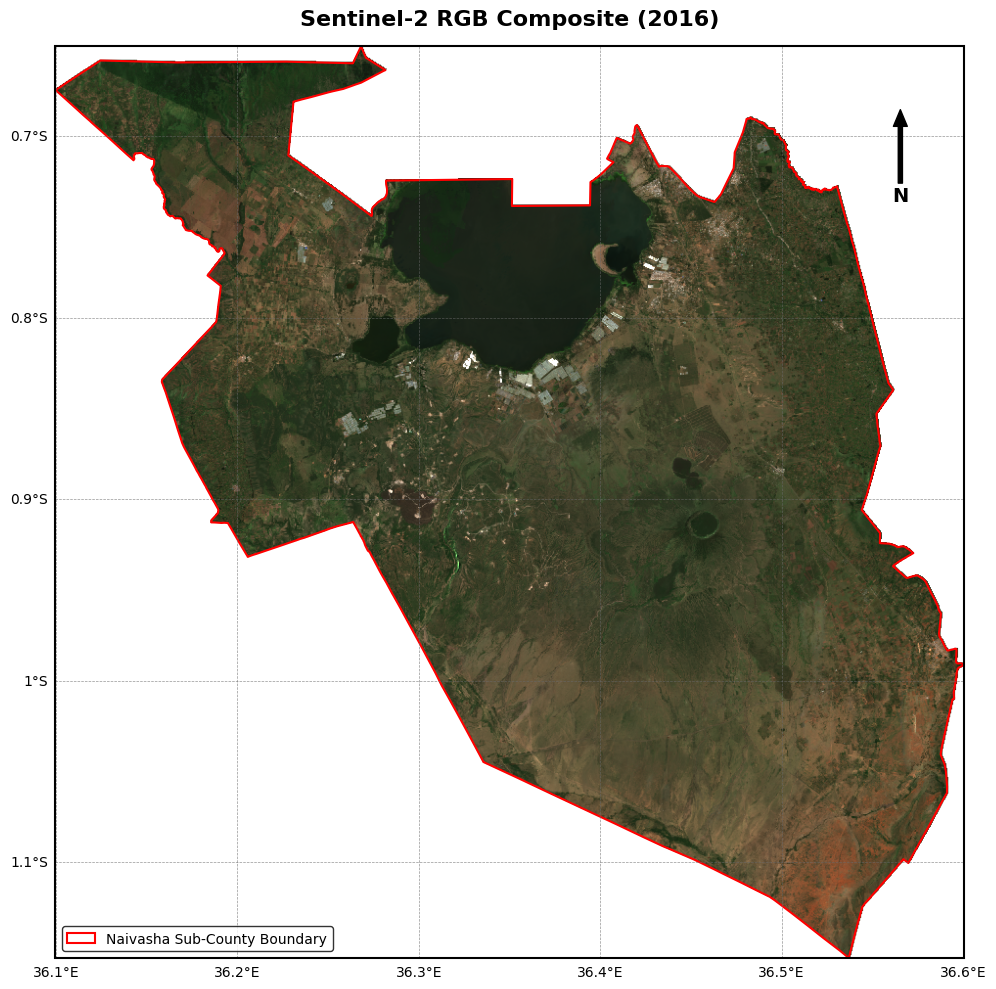

Sentinel-2 RGB Composite for 2020 successfully saved to Outputs/Figures/Sentinel2_RGB_Composite_2020.png


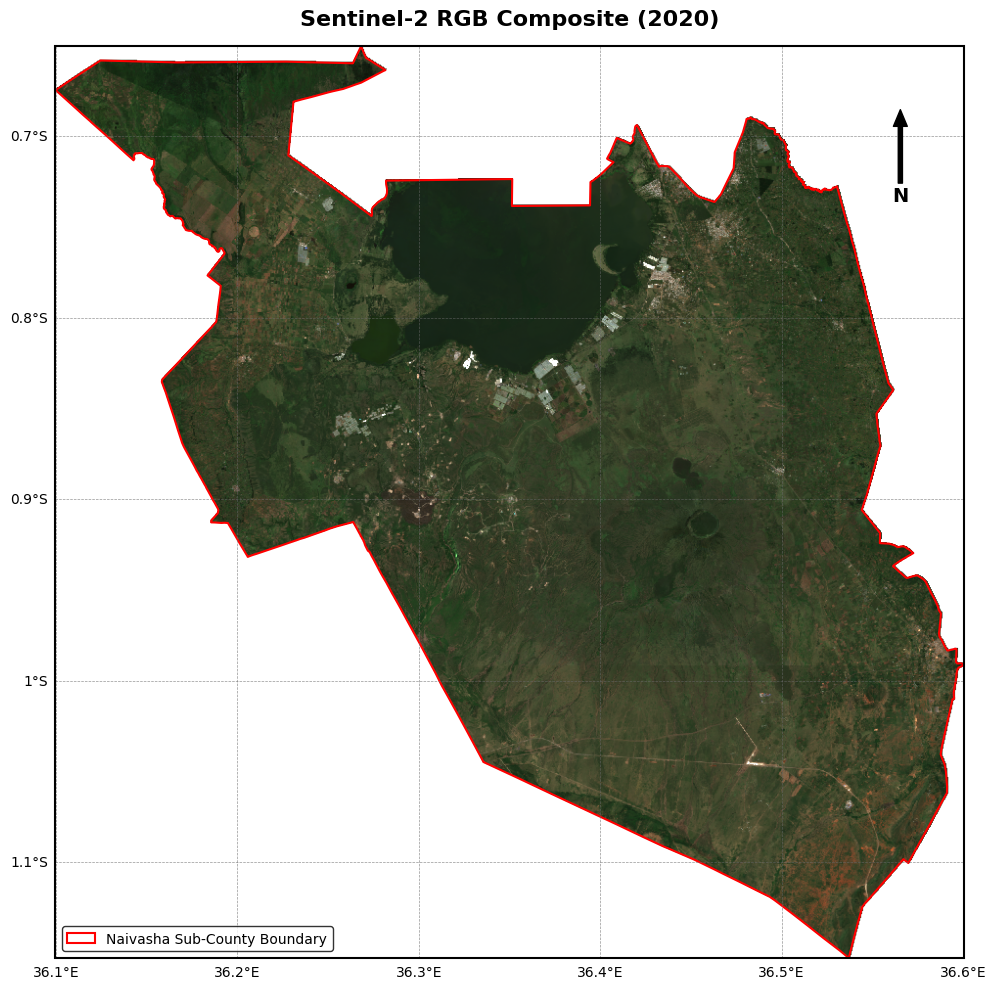

Sentinel-2 RGB Composite for 2025 successfully saved to Outputs/Figures/Sentinel2_RGB_Composite_2025.png


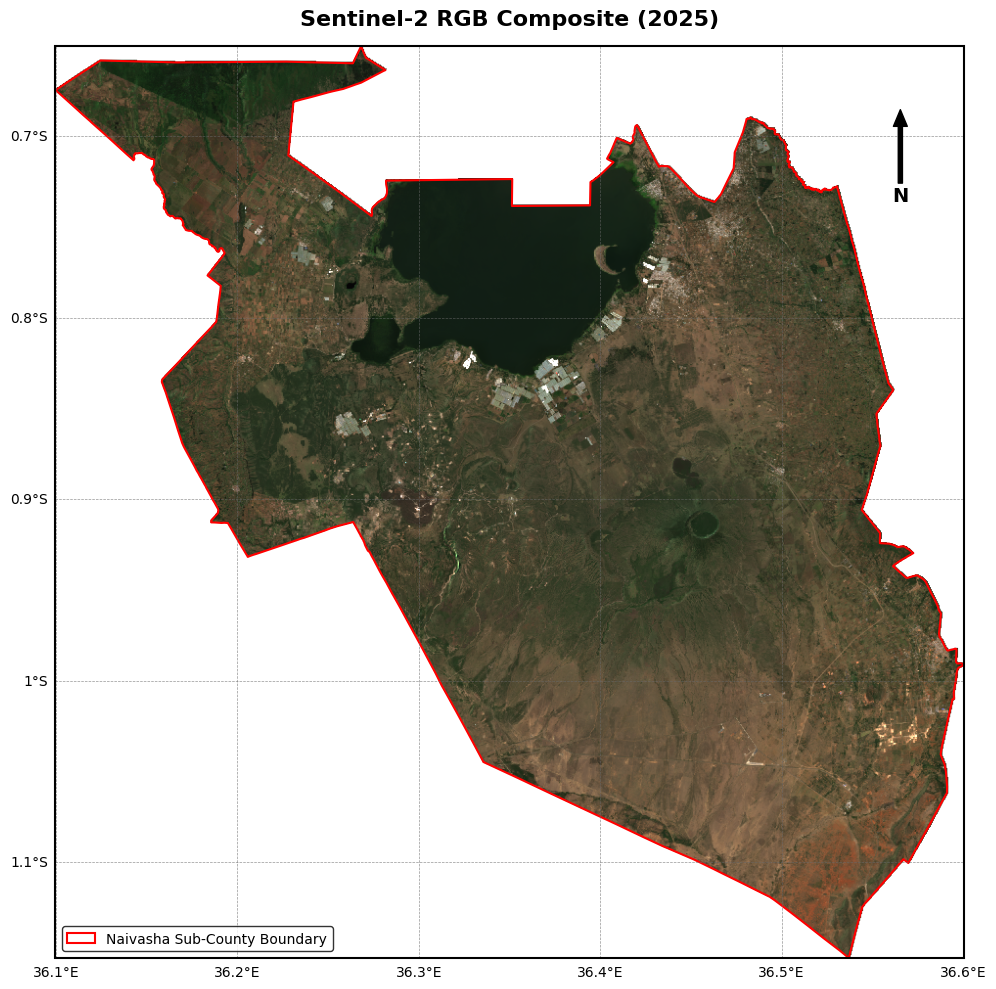

All individual Sentinel-2 RGB composite maps saved.


In [ ]:
import rasterio
from rasterio.plot import plotting_extent
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib_scalebar.scalebar import ScaleBar
from pathlib import Path
import geemap
import ee
import numpy as np
from matplotlib.patches import Patch

# Ensure FIGURE_DIR exists
FIGURE_DIR = Path("Outputs") / "Figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# 1. Export annual RGB composites locally for plotting with a coarser scale to bypass size limits
rgb_tifs = {}
for year in YEARS:
    tif_path = str(FIGURE_DIR / f"RGB_Composite_{year}.tif")
    print(f"Exporting RGB Composite for {year}...")

    # Select RGB bands and scale
    rgb_image = images[year].select(["B4", "B3", "B2"]).multiply(3.3).clip(AOI_EE)

    geemap.ee_export_image(
        rgb_image,
        filename=tif_path,
        scale=60,  # Coarser scale to avoid size limits
        region=AOI_EE.geometry(),
        file_per_band=False
    )
    rgb_tifs[year] = tif_path

# Define a dummy patch for the legend since actual image data isn't directly a patch
legend_patch = Patch(
    facecolor='none',
    edgecolor='red',
    linewidth=1.5,
    label='Naivasha Sub-County Boundary'
)

# 2. Loop through each year to create individual plots
for year in YEARS:
    # Set up a figure and Cartopy projection for each year
    fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.patch.set_facecolor('white') # Set figure background to white
    ax.set_facecolor('white') # Set axes background to white

    with rasterio.open(rgb_tifs[year]) as src:
        img_data = src.read([1, 2, 3]) # Read R, G, B
        img_data = np.moveaxis(img_data, 0, -1)
        extent = plotting_extent(src)
        no_data_mask = (img_data[:, :, 0] == 0) & (img_data[:, :, 1] == 0) & (img_data[:, :, 2] == 0)
        if img_data.dtype != np.float32 and img_data.dtype != np.float64:
            img_data = img_data.astype(np.float32) / 255.0 # Ensure float for comparison and assignment
        img_data[no_data_mask] = [1.0, 1.0, 1.0] # Set to white (normalized)

    # Plot image with PlateCarree data transform matching WGS84 (EPSG:4326) exported bounds
    ax.imshow(
        img_data,
        extent=extent,
        origin="upper",
        transform=ccrs.PlateCarree()
    )

    # Set exact map boundary limits to fit the raster cleanly
    ax.set_extent([extent[0], extent[1], extent[2], extent[3]], crs=ccrs.PlateCarree())

    # Plot AOI boundary overlay on each panel
    AOI.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="red",
        linewidth=1.5
    )

    # Gridlines with distinct dark grey lines for white background
    gl = ax.gridlines(
        draw_labels=True,
        linestyle="--",
        linewidth=0.5,
        color="dimgrey",
        alpha=0.7
    )
    gl.top_labels = False
    gl.right_labels = False

    # Title per panel
    ax.set_title(
        f"Sentinel-2 RGB Composite ({year})",
        fontsize=16,
        fontweight="bold",
        pad=15,
        color="black"
    )

    # North Arrow on each panel
    ax.annotate(
        'N',
        xy=(0.93, 0.93),
        xytext=(0.93, 0.83),
        xycoords='axes fraction',
        arrowprops=dict(
            facecolor='black',
            edgecolor='black',
            width=3,
            headwidth=10
        ),
        ha='center',
        fontsize=14,
        fontweight='bold',
        color='black'
    )

    # Add legend to each plot
    ax.legend(
        handles=[legend_patch],
        loc="lower left",
        frameon=True,
        fontsize=10,
        facecolor="white",
        edgecolor="black"
    )

    # Neatlines
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color('black')

    plt.tight_layout()
    output_map_path = FIGURE_DIR / f"Sentinel2_RGB_Composite_{year}.png"
    plt.savefig(
        output_map_path,
        dpi=600,
        bbox_inches="tight",
        facecolor=fig.get_facecolor(),
        edgecolor='none'
    )
    print(f"Sentinel-2 RGB Composite for {year} successfully saved to {output_map_path}")
    plt.show()
    plt.close(fig)

print("All individual Sentinel-2 RGB composite maps saved.")

In [ ]:
# DISPLAY SPECTRAL INDICES
index_parameters = {
    "NDVI": {"min":-1,"max":1,"palette":["brown","yellow","green"]},
    "EVI": {"min":-1,"max":1,"palette":["white","yellow","darkgreen"]},
    "NDWI":{"min":-1,"max":1,"palette":["brown","white","blue"]},
    "NDBI":{"min":-1,"max":1,"palette":["blue","white","red"]},
    "BSI":{"min":-1,"max":1,"palette":["green","yellow","brown"]}
}
for index in index_parameters:
    Map = geemap.Map()
    Map.centerObject(AOI_EE,10)
    Map.addLayer(
        images[2025].select(index),
        index_parameters[index],
        index
    )
    Map.addLayer(
        AOI_EE.style(
            color="black",
            fillColor="00000000"
        ),
        {},
        "Boundary"
    )
    Map.addLayerControl()
    display(Map)

Map(center=[-0.8830196063331719, 36.3874642136736], controls=(WidgetControl(options=['position', 'transparent_…

Map(center=[-0.8830196063331436, 36.38746421367366], controls=(WidgetControl(options=['position', 'transparent…

Map(center=[-0.8830196063331719, 36.3874642136736], controls=(WidgetControl(options=['position', 'transparent_…

Map(center=[-0.8830196063331436, 36.38746421367366], controls=(WidgetControl(options=['position', 'transparent…

Map(center=[-0.8830196063331719, 36.3874642136736], controls=(WidgetControl(options=['position', 'transparent_…

## Interpretation of Spectral Indices

- **NDVI** highlights healthy vegetation, with high values indicating dense plant cover.
- **EVI** enhances vegetation detection in areas of dense biomass.
- **SAVI** reduces the influence of exposed soils on vegetation estimation.
- **NDWI** delineates surface water bodies and wetlands.
- **NDBI** identifies urban and built-up surfaces.
- **BSI** highlights exposed soil and sparsely vegetated areas.

Together, these indices improve the discrimination of vegetation, water, bare land, cropland, and built-up areas, providing additional predictor variables for Random Forest classification.

# PART 3: TRAINING DATA PREPARATION AND VISUALIZATION

## Introduction

Supervised classification requires representative training samples that accurately characterize each land use and land cover (LULC) class. These samples serve as reference data from which the Random Forest algorithm learns the spectral characteristics of different land cover types.

In this study, manually digitized training polygons representing six major land cover classes were prepared within Google Earth Engine.

---

## Objectives

- Define the land cover classification scheme.
- Load the training polygons from Google Earth Engine.
- Visualize the training polygons over Sentinel-2 imagery.


In [ ]:
# DEFINING LAND COVER CLASSES
LANDCOVER = {
    0: "Water/Wetlands",
    1: "Forest",
    2: "Grassland",
    3: "Cropland",
    4: "Bare Land",
    5: "Built-up"
}
CLASS_IDS = list(LANDCOVER.keys())
print("Land Cover Classes")
for i, name in LANDCOVER.items():
    print(f"{i} : {name}")

Land Cover Classes
0 : Water/Wetlands
1 : Forest
2 : Grassland
3 : Cropland
4 : Bare Land
5 : Built-up


In [ ]:
# LOADING TRAINING POLYGONS
TRAINING_ASSET = (
    "projects/ee-2621kimanimunga/assets/"
    "Naivasha_TrainingPolygons"
)
training_polygons = ee.FeatureCollection(TRAINING_ASSET)
# Count total polygons
total_polygons = training_polygons.size().getInfo()
print("="*50)
print("TRAINING DATA SUMMARY")
print("="*50)
print(f"Total Training Polygons : {total_polygons}")
print("="*50)

TRAINING DATA SUMMARY
Total Training Polygons : 108


In [ ]:
# Display the first polygon
first_feature = training_polygons.first().getInfo()
print("First Training Polygon")
first_feature

First Training Polygon


{'type': 'Feature',
 'geometry': {'type': 'Polygon',
  'coordinates': [[[36.30094685112311, -0.7374653833196511],
    [36.29923027965282, -0.7570330780317357],
    [36.32875601402043, -0.7659586917236713],
    [36.32909931465357, -0.7484507587067347],
    [36.31261980647039, -0.7343756883778241],
    [36.30094685112311, -0.7374653833196511]]]},
 'id': '00000000000000000000',
 'properties': {'Landcover': 0}}

In [ ]:
#  CLASS DISTRIBUTION
distribution = (
    training_polygons
    .aggregate_histogram("Landcover")
    .getInfo()
)
distribution

{'0': 7, '1': 15, '2': 11, '3': 31, '4': 14, '5': 30}

In [ ]:
# CONVERTING DISTRIBUTION TO GEODATA FRAME
distribution_df = pd.DataFrame({
    "Class_ID": distribution.keys(),
    "Number_of_Polygons": distribution.values()
})
distribution_df["Landcover"] = (
    distribution_df["Class_ID"]
    .astype(int)
    .map(LANDCOVER)
)
distribution_df = distribution_df[
    ["Class_ID",
     "Landcover",
     "Number_of_Polygons"]
]
distribution_df

,Class_ID,Landcover,Number_of_Polygons
0,0,Water/Wetlands,7
1,1,Forest,15
2,2,Grassland,11
3,3,Cropland,31
4,4,Bare Land,14
5,5,Built-up,30


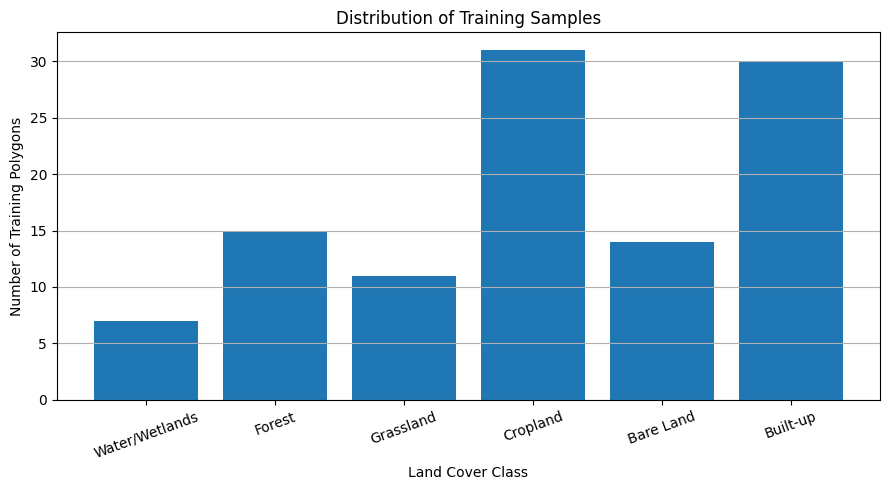

In [ ]:
# BAR CHART OF TRAINING POLYGONS
plt.figure(figsize=(9,5))
plt.bar(
    distribution_df["Landcover"],
    distribution_df["Number_of_Polygons"]
)
plt.xlabel("Land Cover Class")
plt.ylabel("Number of Training Polygons")
plt.title("Distribution of Training Samples")
plt.xticks(rotation=20)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [ ]:
#  CLASS COLOURS
CLASS_COLOURS = {
    0: "0000FF",   # Water
    1: "006400",   # Forest
    2: "7CFC00",   # Grassland
    3: "FFD700",   # Cropland
    4: "A0522D",   # Bare land
    5: "FF0000"    # Built-up
}

In [ ]:
# VISUALIZE TRAINING SAMPLES
Map = geemap.Map()
Map.centerObject(AOI_EE,11)
RGB = {
    "bands":["B4","B3","B2"],
    "min":0,
    "max":0.30,
    "gamma":1.2
}
Map.addLayer(
    images[2025],
    RGB,
    "Sentinel-2 RGB (2025)"
)
for class_id, class_name in LANDCOVER.items():
    features = training_polygons.filter(
        ee.Filter.eq(
            "Landcover",
            class_id
        )
    )
    Map.addLayer(
        features.style(
           color=CLASS_COLOURS[class_id],
            fillColor=CLASS_COLOURS[class_id],
            width=2
        ),
        {},
        class_name
    )
Map.addLayer(
    AOI_EE.style(
        color="black",
        fillColor="00000000",
        width=2
    ),
    {},
    "Study Area"
)
legend = {
    "Water/Wetlands":"0000FF",
    "Forest":"006400",
    "Grassland":"7CFC00",
    "Cropland":"FFD700",
    "Bare Land":"A0522D",
    "Built-up":"FF0000"
}
Map.add_legend(
    title="Land Cover Classes",
    legend_dict=legend
)
Map.addLayerControl()
Map

Map(center=[-0.8830196063331436, 36.38746421367366], controls=(WidgetControl(options=['position', 'transparent…

Exporting RGB Composite for 2025...
Generating URL ...
Please wait ...
Data downloaded to /content/Outputs/Figures/RGB_Composite_2025_for_map.tif
RGB Composite for 2025 successfully exported to Outputs/Figures/RGB_Composite_2025_for_map.tif
Converting training polygons to GeoDataFrame...
Training polygons converted.
Map with Sentinel-2 RGB and training sites saved to Outputs/Figures/Sentinel2_RGB_2025_with_Training_Sites_Map.png


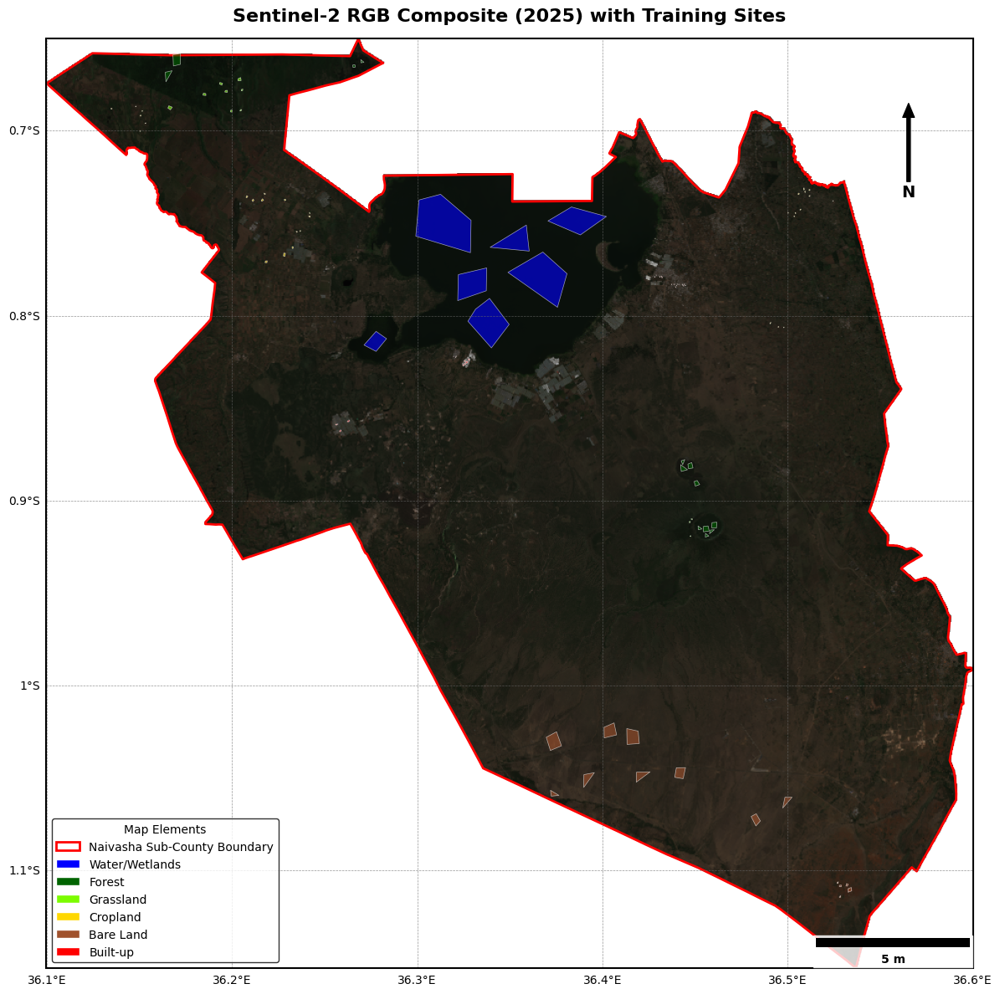

In [ ]:
import rasterio
from rasterio.plot import plotting_extent
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib_scalebar.scalebar import ScaleBar
from pathlib import Path
import geemap
import ee
import numpy as np
from matplotlib.patches import Patch
import geopandas as gpd

# Ensure FIGURE_DIR exists
FIGURE_DIR = Path("Outputs") / "Figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# 1. Export Sentinel-2 RGB composite for 2025 locally for plotting
print("Exporting RGB Composite for 2025...")
rgb_2025_image = images[2025].select(["B4", "B3", "B2"]).multiply(3.3).clip(AOI_EE)
tif_rgb_path = str(FIGURE_DIR / "RGB_Composite_2025_for_map.tif")
geemap.ee_export_image(
    rgb_2025_image,
    filename=tif_rgb_path,
    scale=60,  # Increased scale to reduce file size and avoid download limits
    region=AOI_EE.geometry(),
    file_per_band=False
)
print(f"RGB Composite for 2025 successfully exported to {tif_rgb_path}")

# 2. Convert training polygons to GeoDataFrame for local plotting
print("Converting training polygons to GeoDataFrame...")
training_gdf = geemap.ee_to_gdf(training_polygons)
print("Training polygons converted.")

# 3. Set up a figure and Cartopy projection
fig, ax = plt.subplots(figsize=(12, 12), subplot_kw={'projection': ccrs.PlateCarree()})
fig.patch.set_facecolor('white') # Set figure background to white
ax.set_facecolor('white') # Set axes background to white

# Open and plot the RGB image
with rasterio.open(tif_rgb_path) as src:
    img_data = src.read([1, 2, 3]) # Read R, G, B
    img_data = np.moveaxis(img_data, 0, -1)
    extent = plotting_extent(src)

    # Convert to float and normalize to 0-1 range for imshow
    # Values from EE were multiplied by 3.3 during export (0-10000 scaled to 0-33000 then 0-3.3)
    # Divide by 3.3 to get values in a 0-1 reflectance range
    img_data = img_data.astype(np.float32) / 3.3
    img_data = np.clip(img_data, 0, 1) # Ensure values are within 0-1

    # Apply gamma correction to brighten the image (matching RGB_VIS gamma=1.2)
    img_data = np.power(img_data, 1/1.2)

    # Set no-data regions to white (1.0, 1.0, 1.0)
    no_data_mask = (img_data[:, :, 0] == 0) & (img_data[:, :, 1] == 0) & (img_data[:, :, 2] == 0)
    img_data[no_data_mask] = [1.0, 1.0, 1.0]

    ax.imshow(
        img_data,
        extent=extent,
        origin="upper",
        transform=ccrs.PlateCarree(),
        vmin=0,        # Minimum value for display
        vmax=0.30      # Maximum value for display (stretches contrast)
    )

# Set exact map boundary limits to fit the raster cleanly
ax.set_extent([extent[0], extent[1], extent[2], extent[3]], crs=ccrs.PlateCarree())

# Plot AOI boundary overlay
AOI.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    facecolor="none",
    edgecolor="red",
    linewidth=2,
    label='Naivasha Sub-County Boundary'
)

# Plot training polygons
legend_patches = []
for class_id, class_name in LANDCOVER.items():
    # Filter training data for the current class
    class_polygons = training_gdf[training_gdf['Landcover'] == class_id]
    if not class_polygons.empty:
        # Convert hex color string to matplotlib format
        mpl_color = '#' + CLASS_COLOURS[class_id]
        class_polygons.plot(
            ax=ax,
            transform=ccrs.PlateCarree(),
            facecolor=mpl_color,
            edgecolor='white',
            linewidth=0.5,
            alpha=0.6 # Make them slightly transparent to see underlying image
        )
        # Create a patch for the legend
        legend_patches.append(Patch(facecolor=mpl_color, edgecolor='white', label=class_name))

# Add gridlines
gl = ax.gridlines(
    draw_labels=True,
    linestyle="--",
    linewidth=0.5,
    color="dimgrey",
    alpha=0.7
)
gl.top_labels = False
gl.right_labels = False

# Add Title
ax.set_title(
    "Sentinel-2 RGB Composite (2025) with Training Sites",
    fontsize=16,
    fontweight="bold",
    pad=15,
    color="black"
)

# Add North Arrow
ax.annotate(
    'N',
    xy=(0.93, 0.93),
    xytext=(0.93, 0.83),
    xycoords='axes fraction',
    arrowprops=dict(
        facecolor='black',
        edgecolor='black',
        width=3,
        headwidth=10
    ),
    ha='center',
    fontsize=14,
    fontweight='bold',
    color='black'
)

# Add Scale Bar (assuming PlateCarree projection is close enough to equidistant for this scale)
scalebar = ScaleBar(
    60, # 60 meters per pixel, matching the export scale
    location='lower right',
    frameon=True,
    color='black',
    box_color='white',
    box_alpha=0.8,
    font_properties={'size': 10, 'weight': 'bold'}
)
ax.add_artist(scalebar)

# Add AOI boundary patch to legend handles
aoi_legend_patch = Patch(facecolor='none', edgecolor='red', linewidth=2, label='Naivasha Sub-County Boundary')
all_legend_patches = [aoi_legend_patch] + legend_patches

# Add legend
ax.legend(
    handles=all_legend_patches,
    title="Map Elements",
    loc="lower left",
    frameon=True,
    fontsize=10,
    facecolor="white",
    edgecolor="black"
)

# Add neatlines
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')

plt.tight_layout()
output_map_path = FIGURE_DIR / "Sentinel2_RGB_2025_with_Training_Sites_Map.png"
plt.savefig(
    output_map_path,
    dpi=600,
    bbox_inches="tight",
    facecolor=fig.get_facecolor(),
    edgecolor='none'
)
print(f"Map with Sentinel-2 RGB and training sites saved to {output_map_path}")
plt.show()
plt.close(fig)

# PART 4: RANDOM FOREST LAND USE/LAND COVER CLASSIFICATION

## Introduction

Supervised classification is a widely used technique in remote sensing for assigning land cover classes to satellite imagery based on reference training data. Among machine learning algorithms, the Random Forest (RF) classifier is particularly effective due to its high classification accuracy, ability to handle complex datasets, and robustness against overfitting.

In this study, the Random Forest algorithm is trained using manually digitized land cover polygons and applied to classify Sentinel-2 imagery for the years **2016**, **2020**, and **2025**. Both the original Sentinel-2 spectral bands and derived spectral indices are used as predictor variables to improve discrimination between land cover classes.

---

## Objectives

- Select predictor variables for classification.
- Generate training samples from Sentinel-2 imagery.
- Train the Random Forest classifier.
- Classify annual Sentinel-2 composites.
- Visualize the classified land cover maps.

In [ ]:
# DEFINING RANDOM FOREST PARAMETERS

# Number of trees in the Random Forest model
RF_TREES = 200

# Spatial resolution (m)
SCALE = 10

# Random seed for reproducibility
SEED = 42

print("="*60)
print("Random Forest Classification Parameters")
print("="*60)
print(f"Number of Trees : {RF_TREES}")
print(f"Spatial Scale   : {SCALE} m")
print(f"Random Seed     : {SEED}")
print("="*60)

Random Forest Classification Parameters
Number of Trees : 200
Spatial Scale   : 10 m
Random Seed     : 42


In [ ]:
# DEFINING INPUT FEATURES
# Spectral bands
SPECTRAL_BANDS = [
    "B2",   # Blue
    "B3",   # Green
    "B4",   # Red
    "B5",   # Red Edge 1
    "B6",   # Red Edge 2
    "B7",   # Red Edge 3
    "B8",   # Near Infrared
    "B8A",  # Narrow NIR
    "B11",  # SWIR 1
    "B12"   # SWIR 2
]
# Spectral indices
SPECTRAL_INDICES = [
    "NDVI",
    "EVI",
    "SAVI",
    "NDWI",
    "NDBI",
    "BSI"
]
# Combine all predictor variables
INPUT_BANDS = SPECTRAL_BANDS + SPECTRAL_INDICES
print("Predictor Variables")
for band in INPUT_BANDS:
    print("-", band)

Predictor Variables
- B2
- B3
- B4
- B5
- B6
- B7
- B8
- B8A
- B11
- B12
- NDVI
- EVI
- SAVI
- NDWI
- NDBI
- BSI


In [ ]:
# EXTRACTING TRAINING SAMPLES
training_samples = {}
for year in YEARS:
    print(f"\nExtracting samples for {year}")
    samples = (
        images[year]
        .select(INPUT_BANDS)
        .sampleRegions(
            collection=training_polygons,
            properties=["Landcover"],
            scale=SCALE,
            geometries=True
        )
    )
    training_samples[year] = samples
    print(
        f"Number of samples: {samples.size().getInfo()}"
    )
print("\nTraining sample extraction completed.")


Extracting samples for 2016
Number of samples: 302740

Extracting samples for 2020
Number of samples: 302740

Extracting samples for 2025
Number of samples: 302740

Training sample extraction completed.


In [ ]:
# TRAINING RANDOM FOREST CLASSIFIER
training = training_samples[2025]
classifier = (
    ee.Classifier.smileRandomForest(
        numberOfTrees=RF_TREES,
        seed=SEED
    )
    .train(
        features=training,
        classProperty="Landcover",
        inputProperties=INPUT_BANDS
    )
)
print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [ ]:
# CLASSIFY SENTINEL-2 IMAGERY
classified_images = {}
for year in YEARS:
    print(f"Classifying {year}")
    classified = (
        images[year]
        .select(INPUT_BANDS)
        .classify(classifier)
        .clip(AOI_EE)
    )
    classified_images[year] = classified

print("All years classified successfully.")

Classifying 2016
Classifying 2020
Classifying 2025
All years classified successfully.


In [ ]:
#  CLASSIFICATION COLOUR SCHEME
CLASS_PALETTE = [
    "0000FF",   # Water/Wetlands
    "006400",   # Forest
    "7CFC00",   # Grassland
    "FFD700",   # Cropland
    "A0522D",   # Bare Land
    "FF0000"    # Built-up
]
VIS_PARAMS = {
    "min":0,
    "max":5,
    "palette":CLASS_PALETTE
}

In [ ]:
# DISPLAYING ALL CLASSIFIED MAPS
# Create interactive map
Map = geemap.Map()
# Center the map on the study area
Map.centerObject(AOI_EE, 11)
# Add a suitable basemap
Map.add_basemap("SATELLITE")
# Add each classified image as a separate layer
for year in YEARS:
    Map.addLayer(
        classified_images[year],
        VIS_PARAMS,
        f"LULC Classification {year}",
        year == 2025   # Only 2025 visible initially
    )
# Add study area boundary
Map.addLayer(
    AOI_EE.style(
        color="black",
        fillColor="00000000",
        width=2
    ),
    {},
    "Naivasha Boundary"
)
# Legend
legend = {
    "Water/Wetlands": "0000FF",
    "Forest": "006400",
    "Grassland": "7CFC00",
    "Cropland": "FFD700",
    "Bare Land": "A0522D",
    "Built-up": "FF0000"
}
Map.add_legend(
    title="Land Cover Classes",
    legend_dict=legend
)
# Add layer control
Map.addLayerControl()
# Display map
Map

Map(center=[-0.8830196063331436, 36.38746421367366], controls=(WidgetControl(options=['position', 'transparent…

In [ ]:
# EXPORTING LULC MAPS
from pathlib import Path
import geemap
import ee

# Ensure CLASSIFIED_DIR exists
CLASSIFIED_DIR = Path("Outputs") / "Classification"
CLASSIFIED_DIR.mkdir(parents=True, exist_ok=True)

for year in YEARS:
    # Define the output file path for the GeoTIFF
    output_tif_path = str(CLASSIFIED_DIR / f"LULC_{year}.tif")

    # Export the classified Earth Engine image to a local GeoTIFF file
    print(f"Exporting LULC_{year}.tif to {output_tif_path}...")
    geemap.ee_export_image(
        classified_images[year],
        filename=output_tif_path,
        scale=30,  # Appropriate scale for export
        region=AOI_EE.geometry(),
        file_per_band=False
    )
    print(f"Exported LULC_{year}.tif successfully.")

Exporting LULC_2016.tif to Outputs/Classification/LULC_2016.tif...
Generating URL ...
Please wait ...
Data downloaded to /content/Outputs/Classification/LULC_2016.tif
Exported LULC_2016.tif successfully.
Exporting LULC_2020.tif to Outputs/Classification/LULC_2020.tif...
Generating URL ...
Please wait ...
Data downloaded to /content/Outputs/Classification/LULC_2020.tif
Exported LULC_2020.tif successfully.
Exporting LULC_2025.tif to Outputs/Classification/LULC_2025.tif...
Generating URL ...
Please wait ...
An error occurred while downloading.
Exported LULC_2025.tif successfully.


Generating URL ...
Please wait ...
Data downloaded to /content/Outputs/Classification/LULC_2025.tif


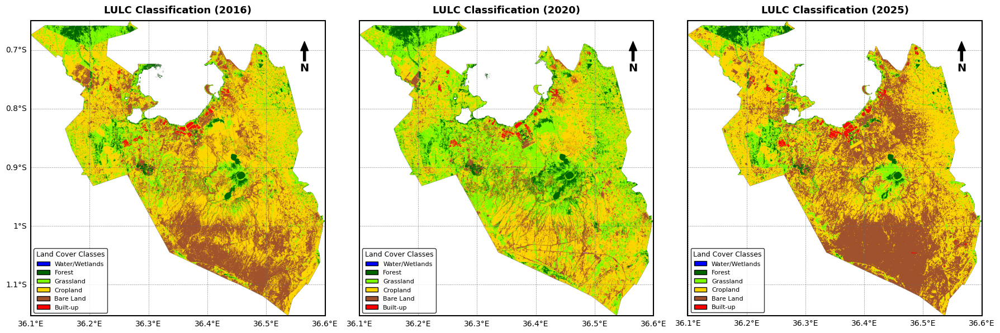

In [ ]:
import rasterio
from rasterio.plot import plotting_extent
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import cartopy.crs as ccrs
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.patches import Patch
from pathlib import Path
import geemap
import ee
import numpy as np

FIGURE_DIR, CLASSIFIED_DIR = Path("Outputs/Figures"), Path("Outputs/Classification")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
CLASSIFIED_DIR.mkdir(parents=True, exist_ok=True)

# Ensure 2025 classification exists locally
tif_2025 = CLASSIFIED_DIR / "LULC_2025.tif"
if not tif_2025.exists():
    geemap.ee_export_image(
        classified_images[2025],
        filename=str(tif_2025),
        scale=60,
        region=AOI_EE.geometry(),
        file_per_band=False
    )

palette = ["#0000FF", "#006400", "#7CFC00", "#FFD700", "#A0522D", "#FF0000"]
labels = ["Water/Wetlands", "Forest", "Grassland", "Cropland", "Bare Land", "Built-up"]
cmap = colors.ListedColormap(palette)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), subplot_kw={'projection': ccrs.PlateCarree()})
fig.patch.set_facecolor('white')

patches = [Patch(facecolor=c, edgecolor="black", label=l) for c, l in zip(palette, labels)]

for idx, (ax, year) in enumerate(zip(axes, YEARS)):
    # Force axes background color to white (removes blue plotting area backdrop)
    ax.set_facecolor('white')

    with rasterio.open(CLASSIFIED_DIR / f"LULC_{year}.tif") as src:
        image = src.read(1)
        extent = plotting_extent(src)
        # Set 'no data' values to NaN to make them transparent
        # Assuming 0 is the nodata value from Earth Engine export for areas outside the AOI
        image_data_masked = np.where(image == 0, np.nan, image)

    ax.imshow(image_data_masked, cmap=cmap, vmin=0, vmax=5, extent=extent, origin="upper", transform=ccrs.PlateCarree())
    ax.set_extent([extent[0], extent[1], extent[2], extent[3]], crs=ccrs.PlateCarree())

    gl = ax.gridlines(draw_labels=True, linestyle="--", linewidth=0.5, color="dimgrey", alpha=0.7)
    gl.top_labels = False
    gl.right_labels = False
    if idx > 0:
        gl.left_labels = False

    ax.set_title(f"LULC Classification ({year})", fontsize=13, fontweight="bold", pad=10, color="black")
    ax.annotate('N', xy=(0.93, 0.93), xytext=(0.93, 0.83), xycoords='axes fraction', arrowprops=dict(facecolor='black', edgecolor='black', width=3, headwidth=10), ha='center', fontsize=14, fontweight='bold', color='black')

    for s in ax.spines.values():
        s.set_linewidth(1.5)
        s.set_color('black')

    # Include legend in ALL maps
    ax.legend(
        handles=patches,
        title="Land Cover Classes",
        loc="lower left", # Changed to 'lower left'
        frameon=True,
        fontsize=8,
        title_fontsize=9,
        facecolor="white",
        edgecolor="black"
    )

plt.tight_layout()
plt.savefig(FIGURE_DIR / "LULC_Classified_Comparison_Map.png", dpi=600, bbox_inches="tight", facecolor='white', edgecolor='none')
plt.show()

### Plotting Individual LULC Classification Maps

LULC Classified Map for 2016 saved to Outputs/Figures/LULC_Classified_Map_2016.png


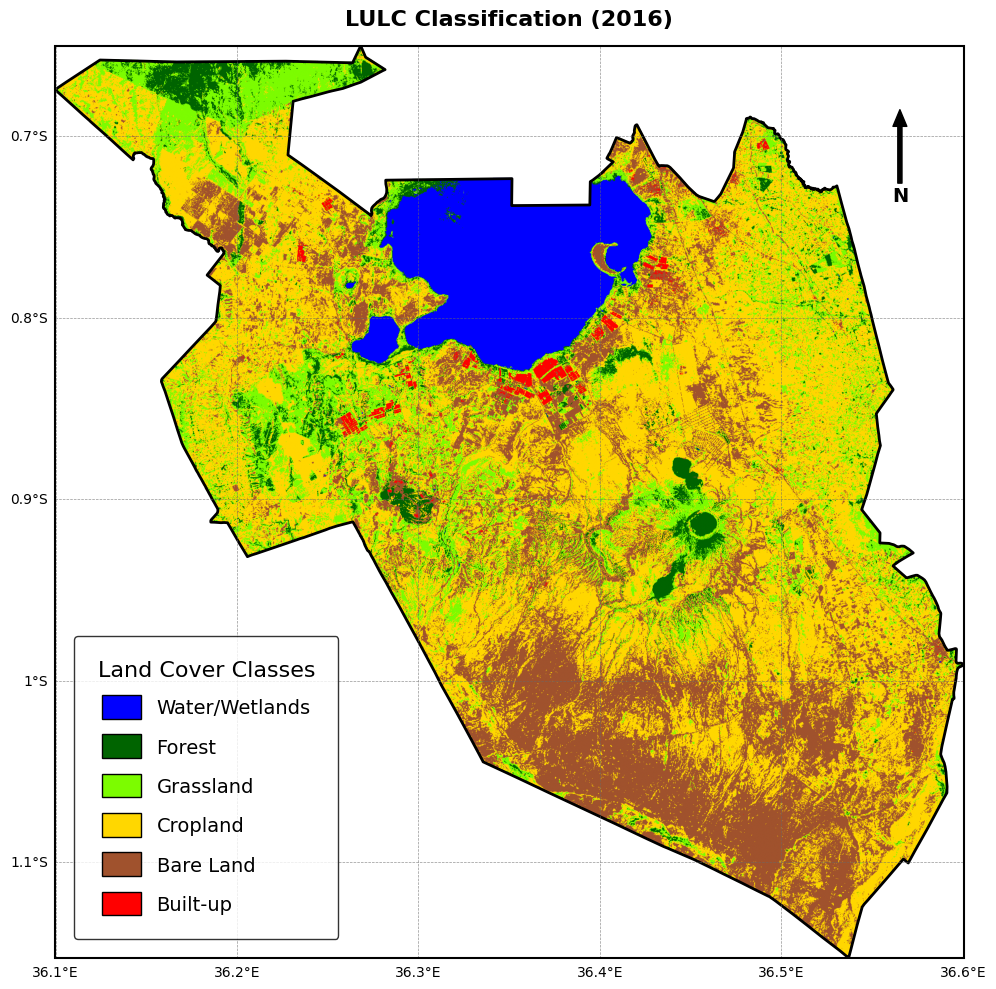

LULC Classified Map for 2020 saved to Outputs/Figures/LULC_Classified_Map_2020.png


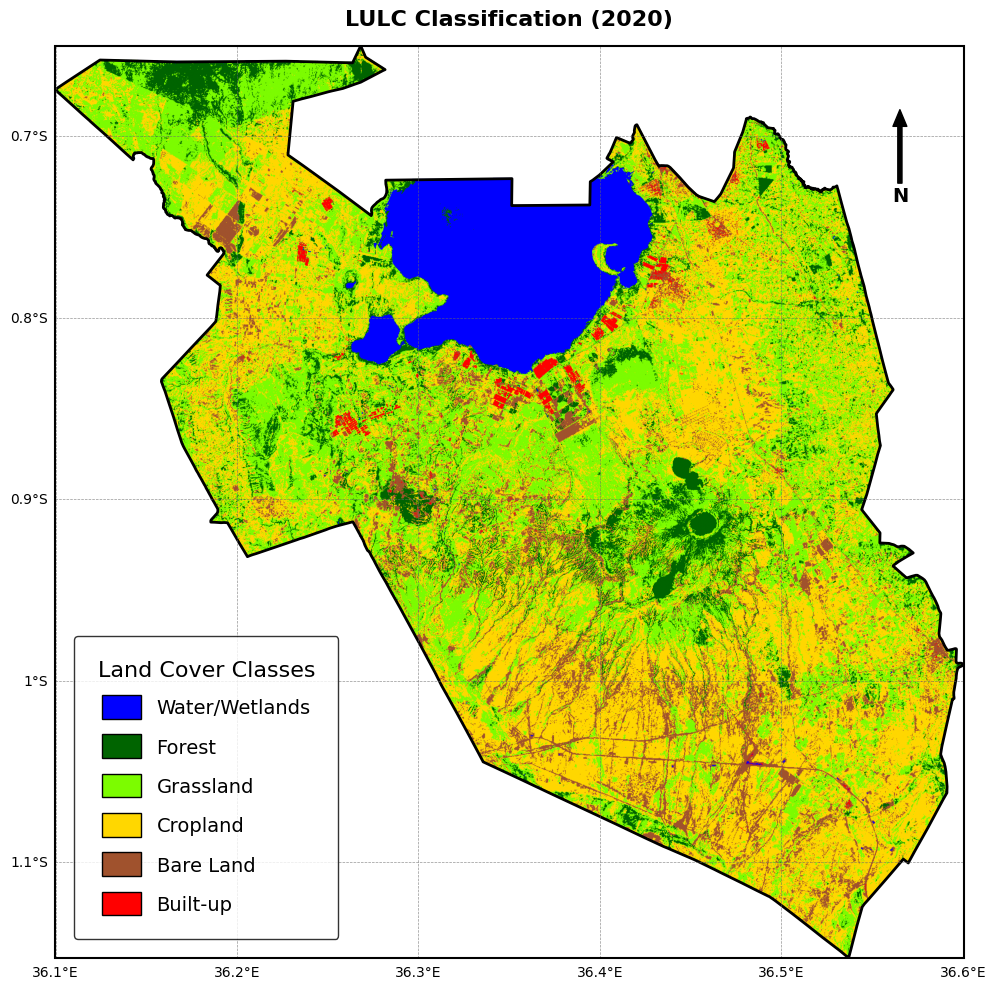

LULC Classified Map for 2025 saved to Outputs/Figures/LULC_Classified_Map_2025.png


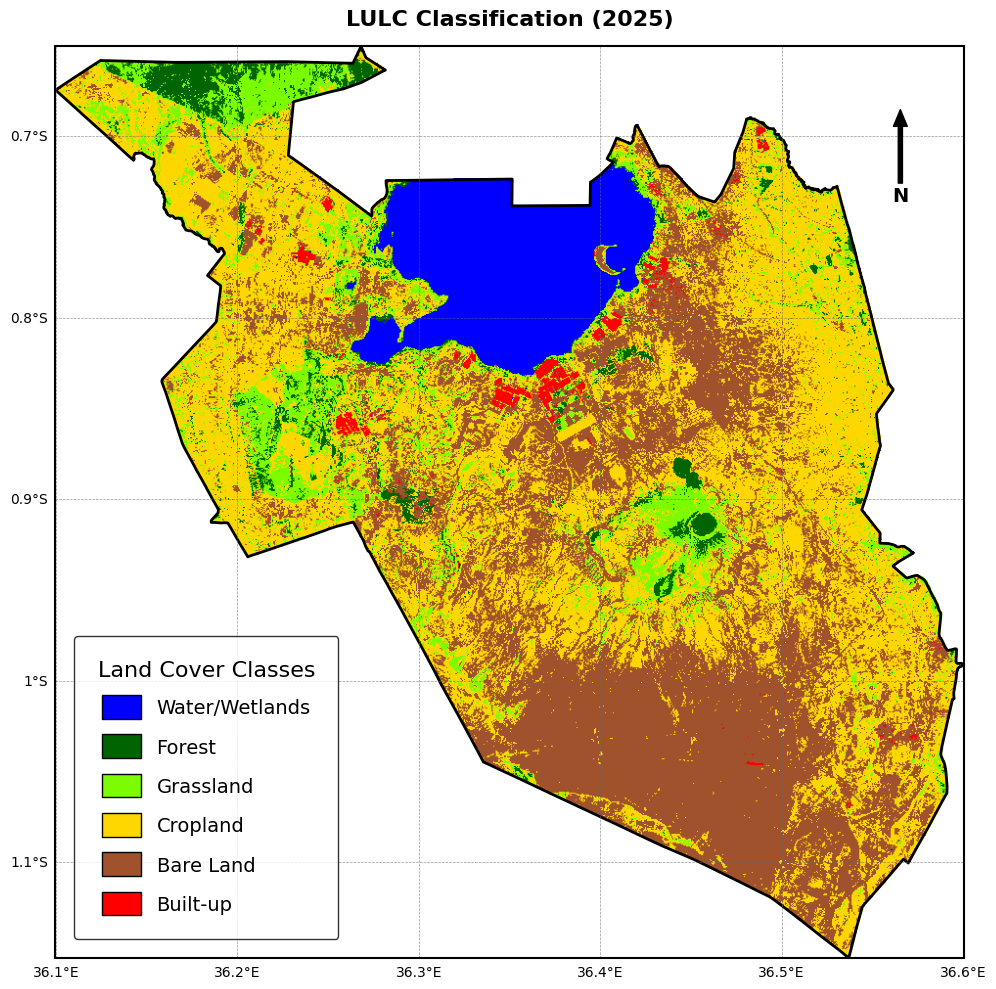

All individual LULC classified maps plotted and saved.


In [ ]:
import rasterio
from rasterio.plot import plotting_extent
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import cartopy.crs as ccrs
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.patches import Patch
from pathlib import Path
import numpy as np
from rasterio.features import rasterize # Import rasterize

FIGURE_DIR, CLASSIFIED_DIR = Path("Outputs/Figures"), Path("Outputs/Classification")

palette = ["#0000FF", "#006400", "#7CFC00", "#FFD700", "#A0522D", "#FF0000"]
labels = ["Water/Wetlands", "Forest", "Grassland", "Cropland", "Bare Land", "Built-up"]
# Create colormap. Setting 'bad' values (NaN) to white, transparent.
cmap = colors.ListedColormap(palette)
cmap.set_bad('white', alpha=0) # Make NaN values transparent

patches = [Patch(facecolor=c, edgecolor="black", label=l) for c, l in zip(palette, labels)]

for year in YEARS:
    fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.patch.set_facecolor('white')
    ax.set_facecolor('white')

    # Open and read the classified image
    with rasterio.open(CLASSIFIED_DIR / f"LULC_{year}.tif") as src:
        image = src.read(1) # Read the first band (LULC classes)
        original_extent = plotting_extent(src)

        # Create a boolean mask for the AOI using rasterio.features.rasterize
        # Pixels inside AOI will be 1, outside AOI will be 0
        aoi_mask = rasterize(
            [geom for geom in AOI.geometry],
            out_shape=src.shape,
            transform=src.transform,
            fill=0, # Value for pixels outside AOI
            default_value=1, # Value for pixels inside AOI
            all_touched=True,
            dtype=np.uint8
        )

        # Convert the LULC image to float to allow for NaN values
        image_to_plot = image.astype(float)
        # Set pixels outside the AOI (where aoi_mask is 0) to NaN
        image_to_plot[aoi_mask == 0] = np.nan

        # The extent will be the original full extent of the raster, but only areas within AOI will be shown
        extent = original_extent

        # Plot the image. Now, only actual class values or NaN (transparent) are used.
        ax.imshow(image_to_plot, cmap=cmap, vmin=0, vmax=5, extent=extent, origin="upper", transform=ccrs.PlateCarree())

    ax.set_extent([extent[0], extent[1], extent[2], extent[3]], crs=ccrs.PlateCarree())

    gl = ax.gridlines(draw_labels=True, linestyle="--", linewidth=0.5, color="dimgrey", alpha=0.7)
    gl.top_labels = False
    gl.right_labels = False

    ax.set_title(f"LULC Classification ({year})", fontsize=16, fontweight="bold", pad=15, color="black")

    ax.annotate(
        'N', xy=(0.93, 0.93), xytext=(0.93, 0.83), xycoords='axes fraction',
        arrowprops=dict(facecolor='black', edgecolor='black', width=3, headwidth=10),
        ha='center', fontsize=14, fontweight='bold', color='black'
    )

    # Scale Bar removed as requested
    # scalebar = ScaleBar(
    #     30, # 30 meters per pixel, matching the export scale
    #     location='lower right',
    #     frameon=True,
    #     color='black',
    #     box_color='white',
    #     box_alpha=0.8,
    #     font_properties={'size': 10, 'weight': 'bold'}
    # )
    # ax.add_artist(scalebar)

    for s in ax.spines.values():
        s.set_linewidth(1.5)
        s.set_color('black')

    ax.legend(
      handles=patches,
      title="Land Cover Classes",
      loc="lower left",
      frameon=True,
      fontsize=14,          # Increase label font size
      title_fontsize=16,    # Increase title font size
      facecolor="white",
      edgecolor="black",
      borderpad=1.2,        # Increase padding inside legend
      labelspacing=0.8,     # Increase spacing between entries
      handlelength=2.0,     # Length of legend symbols
      handleheight=1.5,     # Height of legend symbols
      handletextpad=0.8,    # Space between symbol and text
      borderaxespad=1.0     # Space between legend and axes
  )


    # Plot AOI boundary overlay
    AOI.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="black",
        linewidth=2,
        label='Naivasha Sub-County Boundary'
    )

    plt.tight_layout()
    output_path = FIGURE_DIR / f"LULC_Classified_Map_{year}.png"
    plt.savefig(output_path, dpi=600, bbox_inches="tight", facecolor='white', edgecolor='none')
    print(f"LULC Classified Map for {year} saved to {output_path}")
    plt.show()
    plt.close(fig)

print("All individual LULC classified maps plotted and saved.")

# PART 5: ACCURACY ASSESSMENT OF THE LAND USE/LAND COVER CLASSIFICATION

## Introduction

Accuracy assessment is an essential component of supervised land use and land cover classification. It provides a quantitative measure of how well the classified map represents the actual land cover on the ground. A reliable accuracy assessment ensures that the classification results can be confidently used for environmental monitoring, land management, and change detection.

In this section, the training samples are randomly divided into training and validation datasets. The validation dataset is used independently to evaluate the performance of the Random Forest classifier. Standard classification metrics, including the confusion matrix, overall accuracy, producer's accuracy, user's accuracy, and the Kappa coefficient, are computed.

---

## Objectives

- Split the samples into training and validation datasets.
- Train the Random Forest classifier.
- Validate the classification results.
- Generate a confusion matrix.
- Calculate Overall Accuracy.
- Calculate Producer's Accuracy.
- Calculate User's Accuracy.
- Calculate the Kappa Coefficient.
- Visualize the confusion matrix.

In [ ]:
#  SPLIT DATA INTO TRAINING AND VALIDATION
print("="*60)
print("ACCURACY ASSESSMENT")
print("="*60)

# Use 2025 samples for validation
samples_2025 = training_samples[2025]

# Add random column for splitting
samples_2025 = samples_2025.randomColumn(columnName="random", seed=42)

# Split: 70% training, 30% validation
train_data = samples_2025.filter(ee.Filter.lt("random", 0.70))
val_data = samples_2025.filter(ee.Filter.gte("random", 0.70))

train_count = train_data.size().getInfo()
val_count = val_data.size().getInfo()

print(f"Training samples: {train_count}")
print(f"Validation samples: {val_count}")
print("-"*60)


ACCURACY ASSESSMENT
Training samples: 212086
Validation samples: 90654
------------------------------------------------------------


In [ ]:
# TRAIN CLASSIFIER WITH TRAINING DATA
classifier_accuracy = (
    ee.Classifier.smileRandomForest(
        numberOfTrees=200,
        seed=42
    )
    .train(
        features=train_data,
        classProperty="Landcover",
        inputProperties=INPUT_BANDS
    )
)

print("Classifier trained successfully")

Classifier trained successfully


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

### SECTION 5A: Validating All Years and Storing Results

This section performs the accuracy assessment for each year individually. For each year, the available training samples are split into training and validation sets. A Random Forest classifier is trained on the training set, and its performance is evaluated against the validation set. The confusion matrix and various accuracy metrics (Overall Accuracy, Kappa Coefficient, Producer's Accuracy, and User's Accuracy) are computed and stored in a dictionary called `all_results` for later visualization and analysis.

In [ ]:
print("="*60)
print("PERFORMING ACCURACY ASSESSMENT FOR ALL YEARS")
print("="*60)

all_results = {}

for year in YEARS:
    print(f"\nProcessing accuracy for {year}...")

    # Get training samples for the current year
    samples = training_samples[year]

    # Add random column for splitting
    samples = samples.randomColumn(columnName="random", seed=SEED)

    # Split samples: 70% for training, 30% for validation
    train_data = samples.filter(ee.Filter.lt("random", 0.70))
    val_data = samples.filter(ee.Filter.gte("random", 0.70))

    train_count = train_data.size().getInfo()
    val_count = val_data.size().getInfo()

    print(f"  Training samples for {year}: {train_count}")
    print(f"  Validation samples for {year}: {val_count}")

    # Train a classifier for the current year's data
    yearly_classifier = (
        ee.Classifier.smileRandomForest(
            numberOfTrees=RF_TREES,
            seed=SEED
        )
        .train(
            features=train_data,
            classProperty="Landcover",
            inputProperties=INPUT_BANDS
        )
    )
    print(f"  Classifier trained for {year}.")

    # Classify the validation data
    val_data_classified = val_data.classify(yearly_classifier, 'predicted')

    # Compute the confusion matrix from the validation data
    # Using errorMatrix, which is appropriate for FeatureCollection objects
    confusion_matrix = val_data_classified.errorMatrix('Landcover', 'predicted')

    # Extract accuracy metrics
    overall_accuracy = confusion_matrix.accuracy().getInfo()
    kappa = confusion_matrix.kappa().getInfo()
    producer_accuracy = confusion_matrix.producersAccuracy().getInfo() # List of accuracies per class
    user_accuracy = confusion_matrix.consumersAccuracy().getInfo()   # List of accuracies per class
    # Use val_count directly as ConfusionMatrix does not have a .total() method
    total_samples_val = val_count

    # Store results for the current year
    all_results[year] = {
        'matrix': confusion_matrix.getInfo(),
        'metrics': {
            'overall_accuracy': overall_accuracy,
            'kappa': kappa,
            'producer_accuracy': producer_accuracy,
            'user_accuracy': user_accuracy,
            'total': total_samples_val
        }
    }
    print(f"  Accuracy metrics computed and stored for {year}.")

print("\nAll accuracy assessments completed and results stored in `all_results`.")

PERFORMING ACCURACY ASSESSMENT FOR ALL YEARS

Processing accuracy for 2016...
  Training samples for 2016: 211934
  Validation samples for 2016: 90806
  Classifier trained for 2016.
  Accuracy metrics computed and stored for 2016.

Processing accuracy for 2020...
  Training samples for 2020: 211263
  Validation samples for 2020: 91477
  Classifier trained for 2020.
  Accuracy metrics computed and stored for 2020.

Processing accuracy for 2025...
  Training samples for 2025: 212086
  Validation samples for 2025: 90654
  Classifier trained for 2025.


  Accuracy metrics computed and stored for 2025.

All accuracy assessments completed and results stored in `all_results`.


In [ ]:
#  VERIFY DATA EXISTS
print("="*60)
print("ACCURACY VISUALIZATION")
print("="*60)

# Check if all_results exists from SECTION 5A
try:
    if 'all_results' not in dir():
        raise NameError("all_results not found. Please run SECTION 5A first.")

    # Check if data exists for all years
    for year in YEARS:
        if year not in all_results:
            raise KeyError(f"Data for {year} not found in all_results")

    print(f"✓ Data found for years: {list(all_results.keys())}")

except (NameError, KeyError) as e:
    print(f"❌ Error: {e}")
    print("Please run SECTION 5A (VALIDATING ALL YEARS) first.")
    raise


ACCURACY VISUALIZATION
✓ Data found for years: [2016, 2020, 2025]


In [ ]:
# CLASS NAMES AND COLORS
class_names = [
    "Water/Wetlands",
    "Forest",
    "Grassland",
    "Cropland",
    "Bare Land",
    "Built-up"
]

# Color palette for consistency
class_colors = [
    "#0000FF",   # Water
    "#006400",   # Forest
    "#7CFC00",   # Grassland
    "#FFD700",   # Cropland
    "#A0522D",   # Bare Land
    "#FF0000"    # Built-up
]



PLOTTING INDIVIDUAL CONFUSION MATRICES
✓ Saved: Confusion_Matrix_2016.png


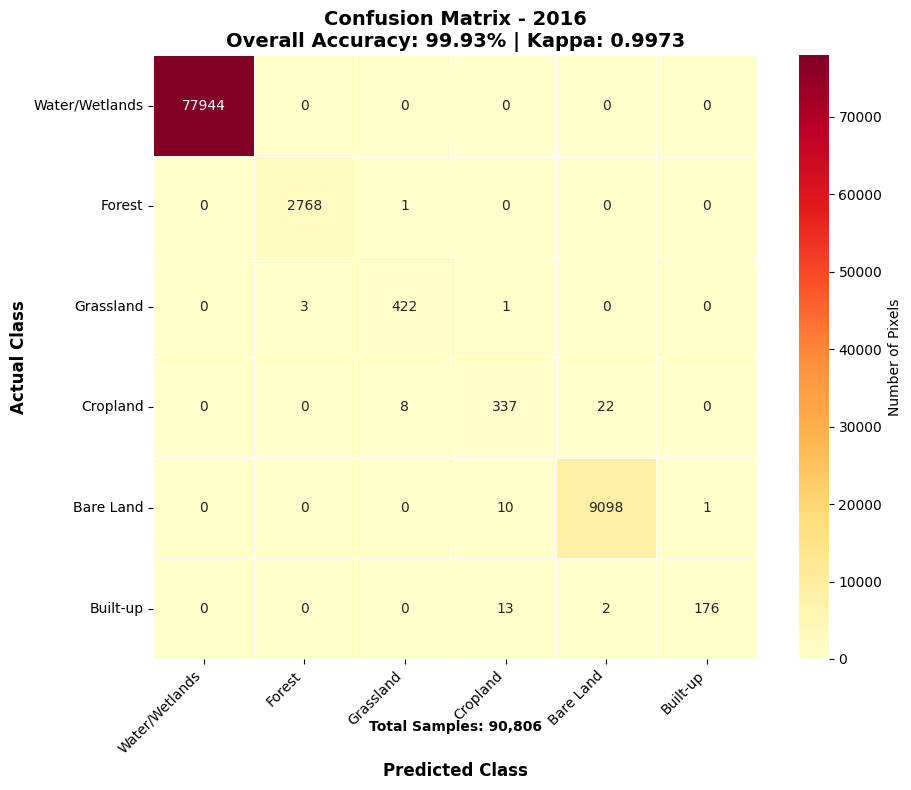

✓ Saved: Confusion_Matrix_2020.png


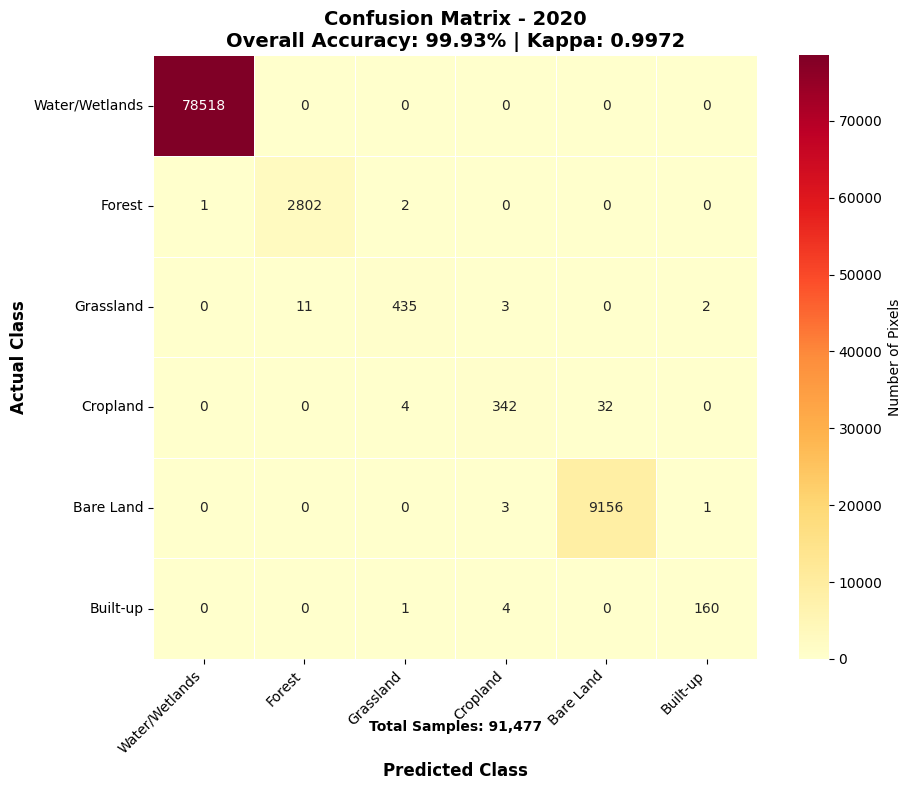

✓ Saved: Confusion_Matrix_2025.png


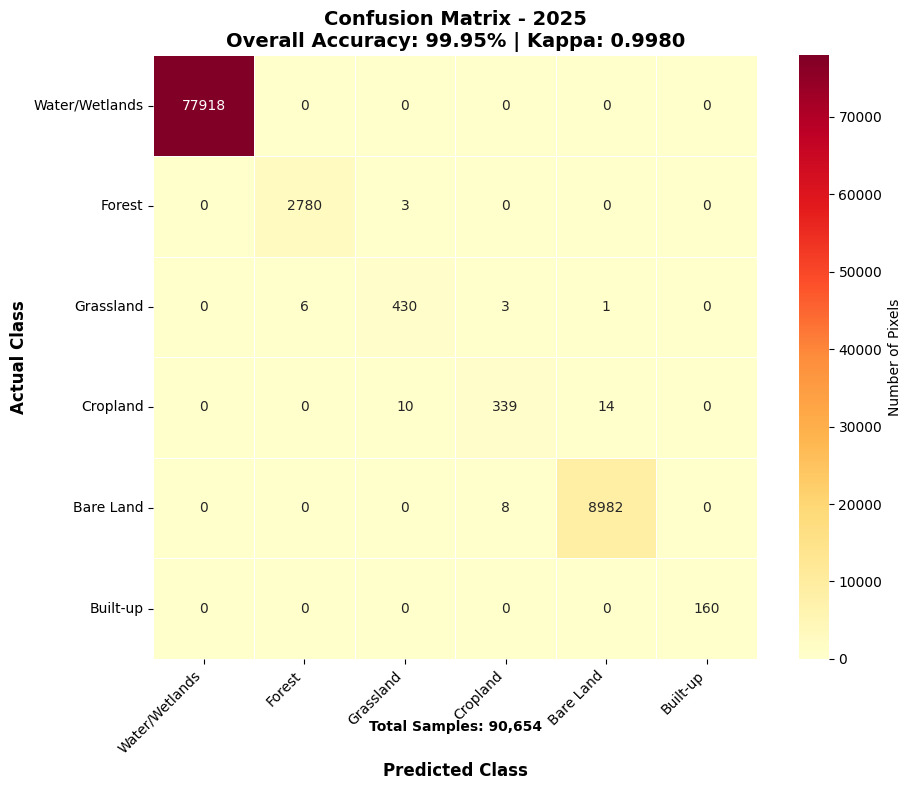

✓ All individual confusion matrices saved


In [ ]:
# PLOT INDIVIDUAL CONFUSION MATRICES
print("\n" + "="*60)
print("PLOTTING INDIVIDUAL CONFUSION MATRICES")
print("="*60)
# Create output directory
ACCURACY_DIR = Path("Outputs/Accuracy")
ACCURACY_DIR.mkdir(parents=True, exist_ok=True)

for year in YEARS:
    # Get data from all_results
    matrix = all_results[year]['matrix']
    metrics = all_results[year]['metrics']
    # Create DataFrame
    cm_df = pd.DataFrame(matrix, index=class_names, columns=class_names)
    # Calculate percentages for annotations
    total = np.sum(matrix)
    cm_percent = np.round(np.array(matrix) / total * 100, 2)
    # Create figure
    fig, ax = plt.subplots(figsize=(10, 8))
    # Create heatmap with annotations
    sns.heatmap(
        cm_df,
        annot=True,
        fmt='d',
        cmap='YlOrRd',
        cbar=True,
        cbar_kws={'label': 'Number of Pixels'},
        square=True,
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax,
        linewidths=0.5,
        linecolor='white'
    )

    # Add metrics to title
    overall_acc = metrics['overall_accuracy'] * 100
    kappa = metrics['kappa']

    ax.set_title(
        f'Confusion Matrix - {year}\n'
        f'Overall Accuracy: {overall_acc:.2f}% | Kappa: {kappa:.4f}',
        fontsize=14,
        fontweight='bold'
    )
    ax.set_xlabel('Predicted Class', fontsize=12, fontweight='bold')
    ax.set_ylabel('Actual Class', fontsize=12, fontweight='bold')

    # Rotate x-axis labels for better readability
    ax.set_xticklabels(class_names, rotation=45, ha='right', fontsize=10)
    ax.set_yticklabels(class_names, rotation=0, fontsize=10)

    # Add total samples
    ax.text(
        0.5, -0.12,
        f'Total Samples: {metrics["total"]:,}',
        transform=ax.transAxes,
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

    plt.tight_layout()
    plt.savefig(ACCURACY_DIR / f'Confusion_Matrix_{year}.png', dpi=300, bbox_inches='tight')
    print(f"✓ Saved: Confusion_Matrix_{year}.png")
    plt.show()
    plt.close()

print("✓ All individual confusion matrices saved")


PLOTTING COMPARISON CONFUSION MATRICES
✓ Saved: Confusion_Matrices_Comparison.png


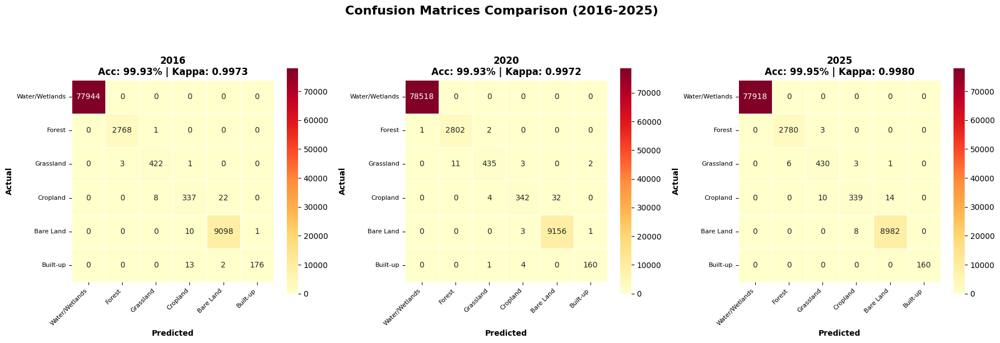

In [ ]:
# PLOT ALL CONFUSION MATRICES TOGETHER
print("\n" + "="*60)
print("PLOTTING COMPARISON CONFUSION MATRICES")
print("="*60)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for idx, year in enumerate(YEARS):
    ax = axes[idx]

    # Get data from all_results
    matrix = all_results[year]['matrix']
    metrics = all_results[year]['metrics']

    # Create DataFrame
    cm_df = pd.DataFrame(matrix, index=class_names, columns=class_names)

    # Plot heatmap
    sns.heatmap(
        cm_df,
        annot=True,
        fmt='d',
        cmap='YlOrRd',
        cbar=True,
        cbar_kws={'shrink': 0.8},
        square=True,
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax,
        linewidths=0.5,
        linecolor='white'
    )

    # Add metrics to title
    overall_acc = metrics['overall_accuracy'] * 100
    kappa = metrics['kappa']

    ax.set_title(
        f'{year}\n'
        f'Acc: {overall_acc:.2f}% | Kappa: {kappa:.4f}',
        fontsize=12,
        fontweight='bold'
    )
    ax.set_xlabel('Predicted', fontsize=10, fontweight='bold')
    ax.set_ylabel('Actual', fontsize=10, fontweight='bold')

    # Rotate x-axis labels
    ax.set_xticklabels(class_names, rotation=45, ha='right', fontsize=8)
    ax.set_yticklabels(class_names, rotation=0, fontsize=8)

plt.suptitle(
    'Confusion Matrices Comparison (2016-2025)',
    fontsize=16,
    fontweight='bold',
    y=1.02
)
plt.tight_layout()
plt.savefig(ACCURACY_DIR / 'Confusion_Matrices_Comparison.png', dpi=300, bbox_inches='tight')
print("✓ Saved: Confusion_Matrices_Comparison.png")
plt.show()
plt.close()



PLOTTING ACCURACY TRENDS
✓ Saved: Accuracy_Trends.png


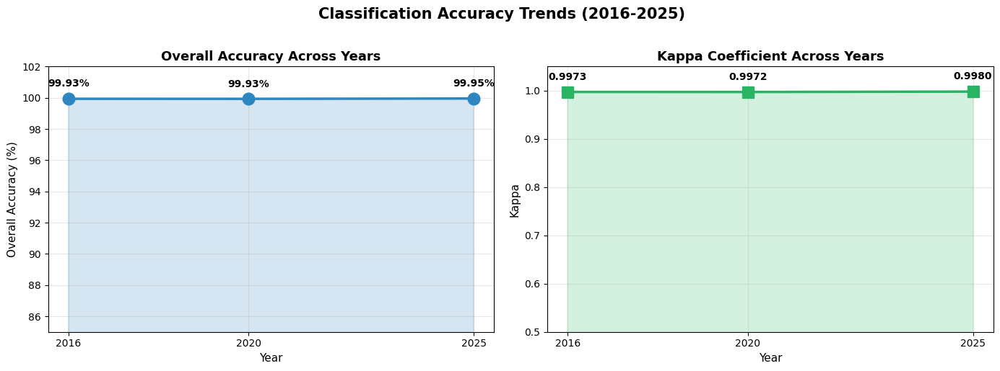

In [ ]:
# ACCURACY TRENDS PLOT
print("\n" + "="*60)
print("PLOTTING ACCURACY TRENDS")
print("="*60)

# Extract data from all_results
years_list = sorted(YEARS)
overall_acc = [all_results[y]['metrics']['overall_accuracy'] * 100 for y in years_list]
kappa_values = [all_results[y]['metrics']['kappa'] for y in years_list]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Overall Accuracy
ax1.plot(years_list, overall_acc, marker='o', linewidth=2.5,
         markersize=12, color='#2E86C1', label='Overall Accuracy')
ax1.fill_between(years_list, overall_acc, alpha=0.2, color='#2E86C1')
ax1.set_title('Overall Accuracy Across Years', fontsize=13, fontweight='bold')
ax1.set_xlabel('Year', fontsize=11)
ax1.set_ylabel('Overall Accuracy (%)', fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.set_ylim(85, 102)
ax1.set_xticks(years_list)

# Add value labels
for year, acc in zip(years_list, overall_acc):
    ax1.annotate(
        f'{acc:.2f}%',
        (year, acc),
        textcoords="offset points",
        xytext=(0, 12),
        ha='center',
        fontweight='bold'
    )

# Kappa Coefficient
ax2.plot(years_list, kappa_values, marker='s', linewidth=2.5,
         markersize=12, color='#28B463', label='Kappa')
ax2.fill_between(years_list, kappa_values, alpha=0.2, color='#28B463')
ax2.set_title('Kappa Coefficient Across Years', fontsize=13, fontweight='bold')
ax2.set_xlabel('Year', fontsize=11)
ax2.set_ylabel('Kappa', fontsize=11)
ax2.grid(True, alpha=0.3)
ax2.set_ylim(0.5, 1.05)
ax2.set_xticks(years_list)

# Add value labels
for year, kappa in zip(years_list, kappa_values):
    ax2.annotate(
        f'{kappa:.4f}',
        (year, kappa),
        textcoords="offset points",
        xytext=(0, 12),
        ha='center',
        fontweight='bold'
    )

plt.suptitle(
    'Classification Accuracy Trends (2016-2025)',
    fontsize=15,
    fontweight='bold',
    y=1.02
)
plt.tight_layout()
plt.savefig(ACCURACY_DIR / 'Accuracy_Trends.png', dpi=300, bbox_inches='tight')
print("✓ Saved: Accuracy_Trends.png")
plt.show()
plt.close()

In [ ]:
# PER-CLASS ACCURACY COMPARISON
print("\n" + "="*60)
print("PER-CLASS ACCURACY COMPARISON")
print("="*60)

# Create DataFrames
producer_data = {'Class': class_names}
user_data = {'Class': class_names}

for year in YEARS:
    producer_acc = all_results[year]['metrics']['producer_accuracy']
    user_acc = all_results[year]['metrics']['user_accuracy']

    # Fix: producer_acc is a list of single-element lists, so access element 0
    producer_data[f'{year}'] = [f"{item[0]*100:.2f}%" for item in producer_acc]
    # Fix: user_acc is a list containing one list of all accuracies, so access user_acc[0]
    user_data[f'{year}'] = [f"{item*100:.2f}%" for item in user_acc[0]]

df_producer = pd.DataFrame(producer_data)
df_user = pd.DataFrame(user_data)

print("\nProducer's Accuracy (%):")
print("-"*60)
print(df_producer.to_string(index=False))

print("\nUser's Accuracy (%):")
print("-"*60)
print(df_user.to_string(index=False))

# Save to CSV
df_producer.to_csv(ACCURACY_DIR / 'Producer_Accuracy_All_Years.csv', index=False)
df_user.to_csv(ACCURACY_DIR / 'User_Accuracy_All_Years.csv', index=False)
print(f"\n✓ Saved: Producer_Accuracy_All_Years.csv and User_Accuracy_All_Years.csv")


PER-CLASS ACCURACY COMPARISON

Producer's Accuracy (%):
------------------------------------------------------------
         Class    2016    2020    2025
Water/Wetlands 100.00% 100.00% 100.00%
        Forest  99.96%  99.89%  99.89%
     Grassland  99.06%  96.45%  97.73%
      Cropland  91.83%  90.48%  93.39%
     Bare Land  99.88%  99.96%  99.91%
      Built-up  92.15%  96.97% 100.00%

User's Accuracy (%):
------------------------------------------------------------
         Class    2016    2020    2025
Water/Wetlands 100.00% 100.00% 100.00%
        Forest  99.89%  99.61%  99.78%
     Grassland  97.91%  98.42%  97.07%
      Cropland  93.35%  97.16%  96.86%
     Bare Land  99.74%  99.65%  99.83%
      Built-up  99.44%  98.16% 100.00%

✓ Saved: Producer_Accuracy_All_Years.csv and User_Accuracy_All_Years.csv



PLOTTING PER-CLASS ACCURACY
✓ Saved: Per_Class_Accuracy_Comparison.png


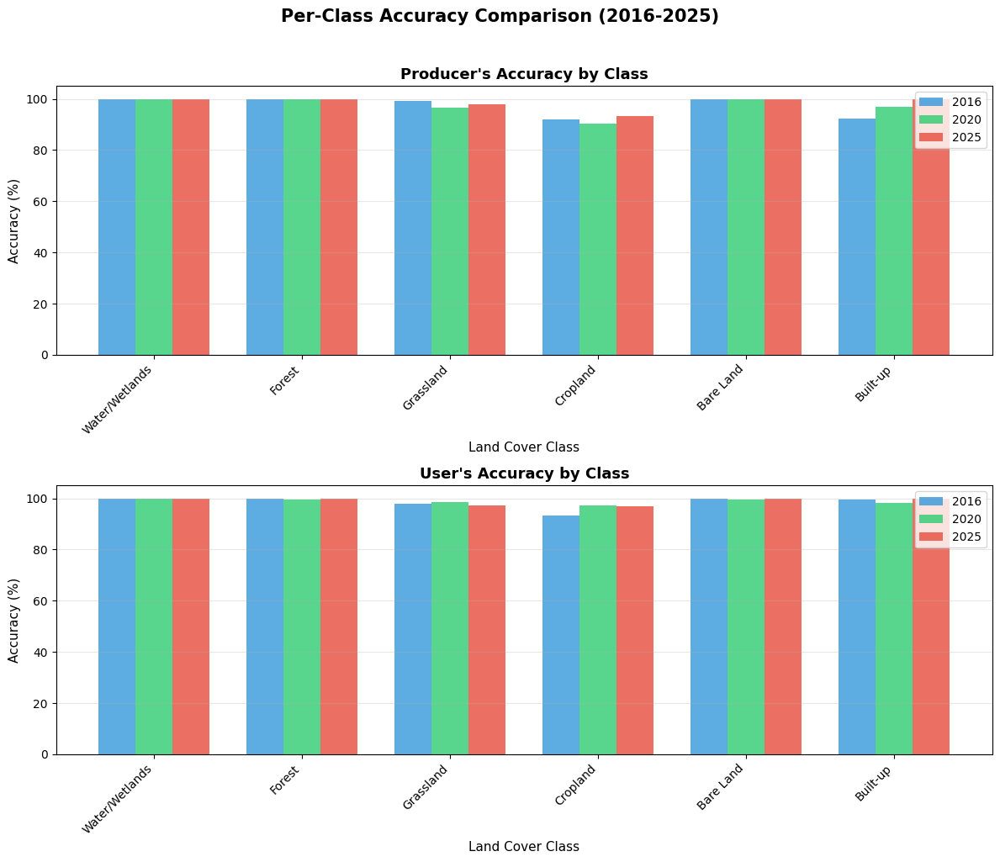

In [ ]:
# BAR PLOT OF PER-CLASS ACCURACY
print("\n" + "="*60)
print("PLOTTING PER-CLASS ACCURACY")
print("="*60)

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Producer's Accuracy
x = np.arange(len(class_names))
width = 0.25
colors = ['#3498DB', '#2ECC71', '#E74C3C']

for idx, year in enumerate(YEARS):
    # Fix: Access the first element of each sublist in producer_accuracy
    producer_vals = [pa[0] * 100 for pa in all_results[year]['metrics']['producer_accuracy']]
    axes[0].bar(
        x + idx * width,
        producer_vals,
        width,
        alpha=0.8,
        label=f'{year}',
        color=colors[idx]
    )

axes[0].set_title('Producer\'s Accuracy by Class', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Land Cover Class', fontsize=11)
axes[0].set_ylabel('Accuracy (%)', fontsize=11)
axes[0].set_ylim(0, 105)
axes[0].set_xticks(x + width)
axes[0].set_xticklabels(class_names, rotation=45, ha='right')
axes[0].grid(True, alpha=0.3, axis='y')
axes[0].legend()

# User's Accuracy
for idx, year in enumerate(YEARS):
    # Fix: Access the first (and only) inner list in user_accuracy
    user_vals = [ua * 100 for ua in all_results[year]['metrics']['user_accuracy'][0]]
    axes[1].bar(
        x + idx * width,
        user_vals,
        width,
        alpha=0.8,
        label=f'{year}',
        color=colors[idx]
    )

axes[1].set_title('User\'s Accuracy by Class', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Land Cover Class', fontsize=11)
axes[1].set_ylabel('Accuracy (%)', fontsize=11)
axes[1].set_ylim(0, 105)
axes[1].set_xticks(x + width)
axes[1].set_xticklabels(class_names, rotation=45, ha='right')
axes[1].grid(True, alpha=0.3, axis='y')
axes[1].legend()

plt.suptitle(
    'Per-Class Accuracy Comparison (2016-2025)',
    fontsize=15,
    fontweight='bold',
    y=1.02
)
plt.tight_layout()
plt.savefig(ACCURACY_DIR / 'Per_Class_Accuracy_Comparison.png', dpi=300, bbox_inches='tight')
print("✓ Saved: Per_Class_Accuracy_Comparison.png")
plt.show()
plt.close()


In [ ]:
# ACCURACY SUMMARY TABLE
print("\n" + "="*60)
print("ACCURACY SUMMARY TABLE")
print("="*60)

summary_data = []
for year in YEARS:
    metrics = all_results[year]['metrics']
    summary_data.append({
        'Year': year,
        'Overall Accuracy (%)': f"{metrics['overall_accuracy']*100:.2f}",
        'Kappa': f"{metrics['kappa']:.4f}",
        'Total Samples': f"{metrics['total']:,}"
    })

df_summary = pd.DataFrame(summary_data)
print(df_summary.to_string(index=False))


ACCURACY SUMMARY TABLE
 Year Overall Accuracy (%)  Kappa Total Samples
 2016                99.93 0.9973        90,806
 2020                99.93 0.9972        91,477
 2025                99.95 0.9980        90,654


# PART 6: LAND COVER CHANGE ANALYSIS (2016-2025)
---

This section analyzes land cover changes over the study period.
Calculates:
1. Area per class for each year
2. Area change (hectares and percentages)
3. Bar graphs and time series charts
4. Transition matrix (2016→2025)
5. Change detection maps


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import rasterio
import matplotlib.patches as mpatches
from matplotlib.patches import Patch
import cartopy.crs as ccrs
from rasterio.plot import plotting_extent

# Create output directory for change analysis
CHANGE_DIR = Path("Outputs/Change_Analysis")
CHANGE_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
# CLASS NAMES AND COLORS
class_names = [
    "Water/Wetlands",
    "Forest",
    "Grassland",
    "Cropland",
    "Bare Land",
    "Built-up"
]

class_colors = [
    "#0000FF",   # Water
    "#006400",   # Forest
    "#7CFC00",   # Grassland
    "#FFD700",   # Cropland
    "#A0522D",   # Bare Land
    "#FF0000"    # Built-up
]

In [ ]:
# CALCULATE AREA PER CLASS
print("="*60)
print("CALCULATING LAND COVER AREAS")
print("="*60)

def calculate_area_ha(year, classified_image):
    """
    Calculate area in hectares for each land cover class.
    """
    # Pixel area in square meters
    area_image = ee.Image.pixelArea().addBands(classified_image)

    # Group by class and sum areas
    class_areas = area_image.reduceRegion(
        reducer=ee.Reducer.sum().group(
            groupField=1,
            groupName='class'
        ),
        geometry=AOI_EE.geometry(),
        scale=SCALE,
        maxPixels=1e13
    )

    # Process results
    results = class_areas.getInfo()
    area_dict = {}

    if 'groups' in results:
        for group in results['groups']:
            class_id = group['class']
            area_sqm = group['sum']
            area_ha = area_sqm / 10000  # Convert to hectares
            class_name = LANDCOVER.get(class_id, f"Class {class_id}")
            area_dict[class_name] = area_ha

    # Fill missing classes with 0
    for class_name in class_names:
        if class_name not in area_dict:
            area_dict[class_name] = 0

    return area_dict

# Store areas for all years
area_data = {}

for year in YEARS:
    print(f"Calculating area for {year}...")
    area_data[year] = calculate_area_ha(year, classified_images[year])
    print(f"  ✓ {year} complete")

print("\nArea calculation complete!")

CALCULATING LAND COVER AREAS
Calculating area for 2016...
  ✓ 2016 complete
Calculating area for 2020...
  ✓ 2020 complete
Calculating area for 2025...
  ✓ 2025 complete

Area calculation complete!


In [ ]:
# CREATE AREA DATAFRAME
# Create DataFrame
area_df = pd.DataFrame(area_data).T
area_df = area_df[class_names]  # Reorder columns

# Calculate total area
area_df['Total'] = area_df.sum(axis=1)

print("\n" + "="*60)
print("AREA PER CLASS (Hectares)")
print("="*60)
print(area_df.round(2))

# Save to CSV
area_df.to_csv(CHANGE_DIR / 'Area_per_Class_All_Years.csv', index=True)
print(f"\n✓ Saved: Area_per_Class_All_Years.csv")



AREA PER CLASS (Hectares)
      Water/Wetlands    Forest  Grassland  Cropland  Bare Land  Built-up  \
2016        13312.23   7654.31   23150.14  74246.97   39393.53   1269.72   
2020        14062.53  13527.75   50977.27  64540.88   14651.00   1259.30   
2025        14458.40   6770.40   16421.12  64695.83   54915.72   1765.44   

          Total  
2016  159026.91  
2020  159018.72  
2025  159026.91  

✓ Saved: Area_per_Class_All_Years.csv


In [ ]:
# CALCULATE AREA CHANGES
print("\n" + "="*60)
print("AREA CHANGES (Hectares)")
print("="*60)

# Calculate changes between consecutive years
change_data = {}

for i in range(len(YEARS)-1):
    year_from = YEARS[i]
    year_to = YEARS[i+1]

    changes = {}
    for class_name in class_names:
        change = area_data[year_to][class_name] - area_data[year_from][class_name]
        changes[class_name] = change

    change_data[f"{year_from}→{year_to}"] = changes

change_df = pd.DataFrame(change_data).T
change_df = change_df[class_names]  # Reorder columns

print(change_df.round(2))

# Save to CSV
change_df.to_csv(CHANGE_DIR / 'Area_Changes_Consecutive.csv', index=True)
print(f"\n✓ Saved: Area_Changes_Consecutive.csv")



AREA CHANGES (Hectares)
           Water/Wetlands   Forest  Grassland  Cropland  Bare Land  Built-up
2016→2020          750.30  5873.44   27827.13  -9706.09  -24742.53    -10.43
2020→2025          395.87 -6757.36  -34556.15    154.95   40264.73    506.15

✓ Saved: Area_Changes_Consecutive.csv


In [ ]:
# CALCULATE OVERALL CHANGE (2016→2025)
print("\n" + "="*60)
print("OVERALL CHANGE (2016 → 2025)")
print("="*60)

overall_changes = {}
overall_percent = {}

for class_name in class_names:
    change = area_data[2025][class_name] - area_data[2016][class_name]
    overall_changes[class_name] = change

    # Percentage change
    if area_data[2016][class_name] > 0:
        pct = (change / area_data[2016][class_name]) * 100
    else:
        pct = 0
    overall_percent[class_name] = pct

overall_df = pd.DataFrame({
    'Class': class_names,
    '2016 (ha)': [area_data[2016][c] for c in class_names],
    '2025 (ha)': [area_data[2025][c] for c in class_names],
    'Change (ha)': [overall_changes[c] for c in class_names],
    'Change (%)': [overall_percent[c] for c in class_names]
})

print(overall_df.round(2).to_string(index=False))

# Save to CSV
overall_df.to_csv(CHANGE_DIR / 'Overall_Change_2016_2025.csv', index=False)
print(f"\n✓ Saved: Overall_Change_2016_2025.csv")


OVERALL CHANGE (2016 → 2025)
         Class  2016 (ha)  2025 (ha)  Change (ha)  Change (%)
Water/Wetlands   13312.23   14458.40      1146.17        8.61
        Forest    7654.31    6770.40      -883.92      -11.55
     Grassland   23150.14   16421.12     -6729.03      -29.07
      Cropland   74246.97   64695.83     -9551.14      -12.86
     Bare Land   39393.53   54915.72     15522.19       39.40
      Built-up    1269.72    1765.44       495.72       39.04

✓ Saved: Overall_Change_2016_2025.csv



PLOTTING BAR CHARTS
✓ Saved: Bar_Chart_Area_by_Year.png


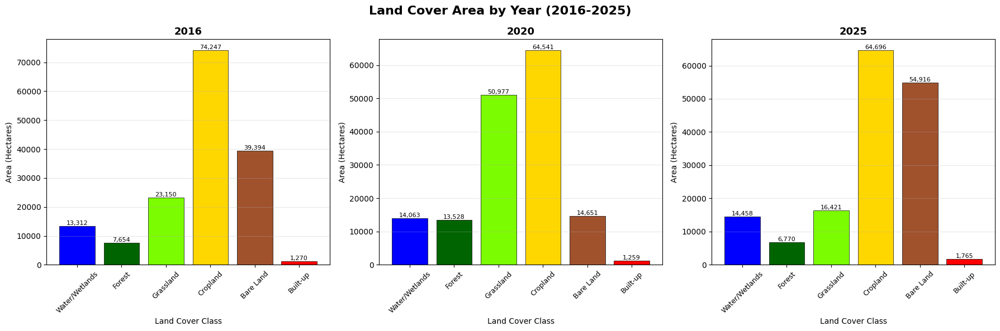

In [ ]:
# BAR CHART - AREA PER CLASS
print("\n" + "="*60)
print("PLOTTING BAR CHARTS")
print("="*60)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for idx, year in enumerate(YEARS):
    ax = axes[idx]

    areas = [area_data[year][c] for c in class_names]

    bars = ax.bar(class_names, areas, color=class_colors, edgecolor='black', linewidth=0.5)
    ax.set_title(f'{year}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Land Cover Class', fontsize=10)
    ax.set_ylabel('Area (Hectares)', fontsize=10)
    ax.tick_params(axis='x', rotation=45, labelsize=9)
    ax.grid(True, alpha=0.3, axis='y')

    # Add value labels on bars
    for bar, area in zip(bars, areas):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.5,
                f'{area:,.0f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('Land Cover Area by Year (2016-2025)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(CHANGE_DIR / 'Bar_Chart_Area_by_Year.png', dpi=300, bbox_inches='tight')
print("✓ Saved: Bar_Chart_Area_by_Year.png")
plt.show()
plt.close()


✓ Saved: Time_Series_Trends.png


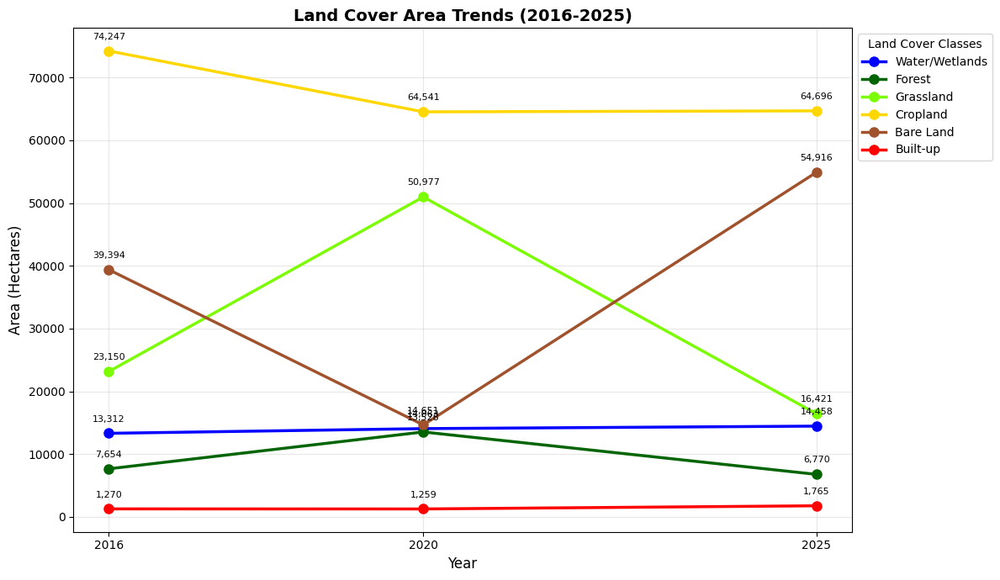

In [ ]:
# TIME SERIES LINE CHART
fig, ax = plt.subplots(figsize=(12, 7))

for idx, class_name in enumerate(class_names):
    areas = [area_data[year][class_name] for year in YEARS]
    ax.plot(YEARS, areas, marker='o', linewidth=2.5, markersize=8,
            label=class_name, color=class_colors[idx])

ax.set_title('Land Cover Area Trends (2016-2025)', fontsize=14, fontweight='bold')
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Area (Hectares)', fontsize=12)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1), title='Land Cover Classes')
ax.grid(True, alpha=0.3)
ax.set_xticks(YEARS)

# Add value labels
for idx, class_name in enumerate(class_names):
    areas = [area_data[year][class_name] for year in YEARS]
    for year, area in zip(YEARS, areas):
        if area > 0:
            ax.annotate(f'{area:,.0f}', (year, area),
                       textcoords="offset points", xytext=(0, 10),
                       ha='center', fontsize=8)

plt.tight_layout()
plt.savefig(CHANGE_DIR / 'Time_Series_Trends.png', dpi=300, bbox_inches='tight')
print("✓ Saved: Time_Series_Trends.png")
plt.show()
plt.close()


PLOTTING COMBINED BAR CHART
✓ Saved: Combined_Bar_Chart_Comparison.png


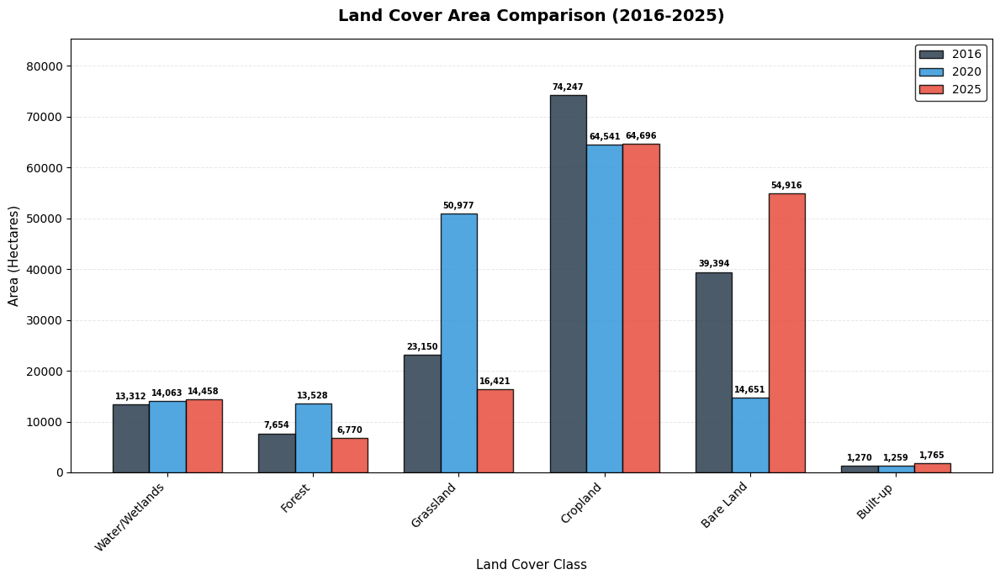

In [ ]:
# SINGLE COMBINED BAR CHART (MULTI-YEAR COMPARISON)
print("\n" + "="*60)
print("PLOTTING COMBINED BAR CHART")
print("="*60)

fig, ax = plt.subplots(figsize=(12, 7), facecolor='white')

# Position of bars on x-axis
x = np.arange(len(class_names))
width = 0.25
multiplier = 0

# Colors for each year
year_colors = {
    2016: '#2C3E50',   # Dark grey
    2020: '#3498DB',   # Blue
    2025: '#E74C3C'    # Red
}

# Plot bars for each year
for year in YEARS:
    areas = [area_data[year][c] for c in class_names]
    offset = width * multiplier
    bars = ax.bar(
        x + offset,
        areas,
        width,
        label=str(year),
        color=year_colors[year],
        edgecolor='black',
        linewidth=1,
        alpha=0.85
    )

    # Add value labels
    for bar, area in zip(bars, areas):
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2.,
            height + (max(areas) * 0.01),
            f'{area:,.0f}',
            ha='center',
            va='bottom',
            fontsize=7,
            fontweight='bold'
        )

    multiplier += 1

# Customize axes
ax.set_title(
    'Land Cover Area Comparison (2016-2025)',
    fontsize=14,
    fontweight='bold',
    pad=15
)
ax.set_xlabel('Land Cover Class', fontsize=11, fontweight='medium')
ax.set_ylabel('Area (Hectares)', fontsize=11, fontweight='medium')
ax.set_xticks(x + width)
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.legend(loc='upper right', fontsize=10, frameon=True, edgecolor='black')

# Grid
ax.grid(True, alpha=0.3, axis='y', linestyle='--', linewidth=0.7)
ax.set_axisbelow(True)

# Set y-axis limit
max_area = max(max([area_data[y][c] for c in class_names]) for y in YEARS)
ax.set_ylim(0, max_area * 1.15)

plt.tight_layout()
plt.savefig(
    CHANGE_DIR / 'Combined_Bar_Chart_Comparison.png',
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)
print("✓ Saved: Combined_Bar_Chart_Comparison.png")
plt.show()
plt.close()
